In [1]:
import warnings

warnings.filterwarnings("ignore")

import os
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

RESULTS_PATH = "results.csv"

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

RESET_RESULTS = False # reset
RESULT_COLUMNS = [
    "experiment", "model", "representation", "max_length", "pct_tokens_retained",
    "vocab_size", "embedding_dim", "hidden_size", "params", "rnn_params",
    "epochs_run", "best_epoch", "train_time_sec", "best_val_loss",
    "accuracy", "precision", "recall", "f1", "seed", "notes",
]

if RESET_RESULTS and os.path.exists(RESULTS_PATH):
    os.remove(RESULTS_PATH)


def log_result(**kwargs):
    row = {c: kwargs.get(c, None) for c in RESULT_COLUMNS}
    need_header = (not os.path.exists(RESULTS_PATH)) or os.path.getsize(RESULTS_PATH) == 0
    pd.DataFrame([row], columns=RESULT_COLUMNS).to_csv(
        RESULTS_PATH, mode="a", header=need_header, index=False)
    return row


def compute_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }

In [2]:
import re

TOKEN_RE = re.compile(r"[a-z0-9]+(?:'[a-z]+)?|[!?]")


def clean_text(text):
    text = str(text).lower()
    return re.sub(r"<br\s*/?>", " ", text)


def tokenize(text):
    return TOKEN_RE.findall(clean_text(text))


print(tokenize("I did NOT like this movie!<br /><br />It wasn't good."))

['i', 'did', 'not', 'like', 'this', 'movie', '!', 'it', "wasn't", 'good']


### Experiment 1: Dataset inspection

In [3]:
DATA_PATH = os.path.join("..", "data", "IMDB Dataset.csv")

df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
df_raw.head()

Shape: (50000, 2)
Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
LABEL_COL = "sentiment"

n_samples = len(df_raw)
classes = df_raw[LABEL_COL].dropna().unique().tolist()
print(f"Số samples: {n_samples:,}")
print(f"Số classes: {len(classes)} -> {classes}")

Số samples: 50,000
Số classes: 2 -> ['positive', 'negative']


In [5]:
TEXT_COL = "review"

text_s, label_s = df_raw[TEXT_COL], df_raw[LABEL_COL]

missing_text = int(text_s.isna().sum())
empty_text = int((text_s.dropna().str.strip() == "").sum())
missing_label = int(label_s.isna().sum())
n_dup = int(df_raw.duplicated(subset=[TEXT_COL], keep="first").sum())
n_dup_rows_all = int(df_raw.duplicated(subset=[TEXT_COL], keep=False).sum())

# review trùng nhau nhưng khác nhãn 
conflict = (df_raw.dropna(subset=[TEXT_COL, LABEL_COL])
            .groupby(TEXT_COL)[LABEL_COL].nunique())
n_conflict = int((conflict > 1).sum())

print(f"Missing text: {missing_text}")
print(f"Empty text (chuỗi rỗng): {empty_text}")
print(f"Missing label: {missing_label}")
print(f"Duplicate documents: {n_dup} dòng trùng (tổng số dòng liên quan: {n_dup_rows_all})")
print(f"Duplicate khác nhãn: {n_conflict}")

Missing text: 0
Empty text (chuỗi rỗng): 0
Missing label: 0
Duplicate documents: 418 dòng trùng (tổng số dòng liên quan: 824)
Duplicate khác nhãn: 0


In [6]:
LABEL2ID = {"negative": 0, "positive": 1}
DROP_DUPLICATES = True # bỏ review trùng nhau 

df = df_raw.dropna(subset=[TEXT_COL, LABEL_COL]).copy()
df = df[df[TEXT_COL].str.strip() != ""]
if DROP_DUPLICATES:
    df = df.drop_duplicates(subset=[TEXT_COL], keep="first")
df["label"] = df[LABEL_COL].map(LABEL2ID)
df = df.reset_index(drop=True)
print(f"Sau làm sạch: {len(df):,} samples (bỏ {len(df_raw) - len(df):,} dòng)")

Sau làm sạch: 49,582 samples (bỏ 418 dòng)


,count,percent
sentiment,,
positive,24884,50.19
negative,24698,49.81


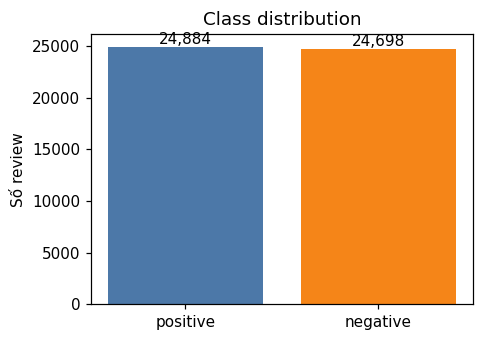

In [7]:
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

dist = df[LABEL_COL].value_counts()
dist_df = pd.DataFrame({"count": dist, "percent": (dist / dist.sum() * 100).round(2)})
display(dist_df)

fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.bar(dist.index, dist.values, color=["#4C78A8", "#F58518"])
ax.set_ylabel("Số review"); ax.set_title("Class distribution")
for i, v in enumerate(dist.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

In [8]:
import time

# Độ dài bằng số token sau khi tokenize ở phía trên
t0 = time.perf_counter()
df["tokens"] = df[TEXT_COL].map(tokenize)
df["length"] = df["tokens"].map(len)
print(f"Tokenize xong trong {time.perf_counter() - t0:.1f}s")

len_stats = df["length"].describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(1)
display(len_stats.to_frame("sequence length"))

print(f"Minimum sequence length: {df['length'].min()}")
print(f"Median sequence length: {df['length'].median():.0f}")
print(f"Mean sequence length: {df['length'].mean():.1f}")
print(f"Maximum sequence length: {df['length'].max()}")
display(df.groupby(LABEL_COL)["length"].describe().round(1))

Tokenize xong trong 6.2s


,sequence length
count,49582.0
mean,232.8
std,171.9
min,7.0
25%,128.0
50%,175.0
75%,282.0
90%,454.0
95%,592.0
99%,908.0


Minimum sequence length: 7
Median sequence length: 175
Mean sequence length: 232.8
Maximum sequence length: 2503


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,24698.0,231.3,165.7,7.0,129.0,176.0,280.0,1530.0
positive,24884.0,234.3,177.8,10.0,126.0,174.0,285.0,2503.0


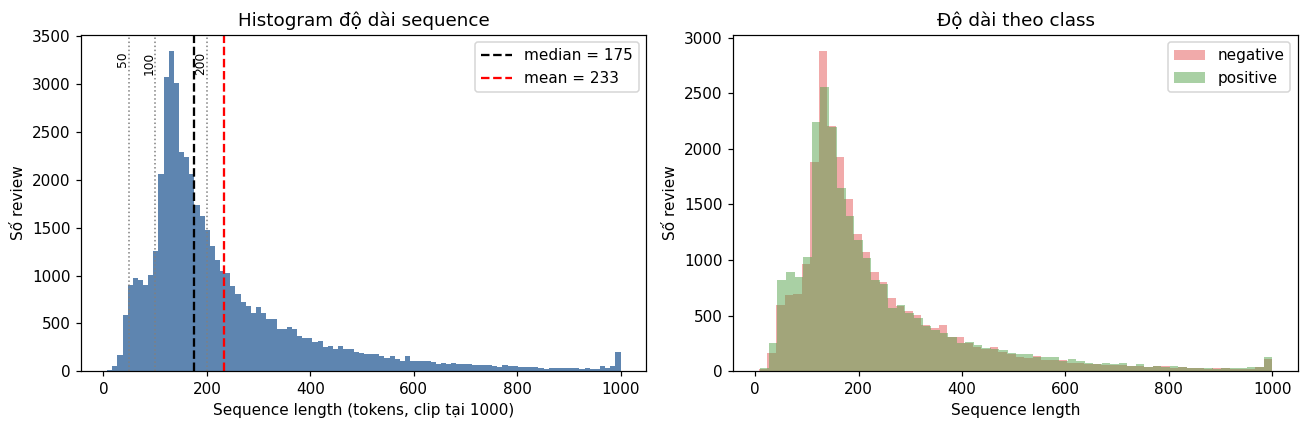

In [9]:
LENGTH_GRID = [50, 100, 200]

CLIP_X = 1000   
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.hist(df["length"].clip(upper=CLIP_X), bins=100, color="#4C78A8", alpha=0.9)
ax.axvline(df["length"].median(), color="k", ls="--", label=f"median = {df['length'].median():.0f}")
ax.axvline(df["length"].mean(), color="r", ls="--", label=f"mean = {df['length'].mean():.0f}")
for L in LENGTH_GRID:
    ax.axvline(L, color="gray", ls=":", lw=1)
    ax.text(L, ax.get_ylim()[1] * 0.95, str(L), rotation=90, va="top", ha="right", fontsize=8)
ax.set_xlabel(f"Sequence length (tokens, clip tại {CLIP_X})"); ax.set_ylabel("Số review")
ax.set_title("Histogram độ dài sequence"); ax.legend()

ax = axes[1]
for lab, color in [("negative", "#E45756"), ("positive", "#54A24B")]:
    ax.hist(df.loc[df[LABEL_COL] == lab, "length"].clip(upper=CLIP_X), bins=60,
            alpha=0.5, label=lab, color=color)
ax.set_xlabel("Sequence length"); ax.set_ylabel("Số review")
ax.set_title("Độ dài theo class"); ax.legend()

plt.tight_layout()
plt.savefig("length_histogram.png", bbox_inches="tight")
plt.show()

,max_length,% docs not truncated,% tokens retained
0,30,0.22,12.88
1,50,2.36,21.39
2,100,12.14,41.34
3,128,25.50,51.28
4,200,58.60,68.51
5,256,71.14,76.86
6,300,77.48,81.71
7,400,86.94,89.16
8,500,92.11,93.57


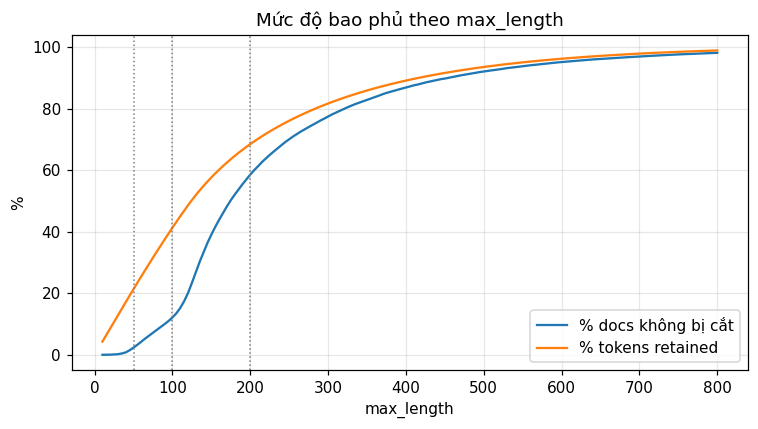

In [10]:
import numpy as np

def pct_tokens_retained(lengths, L):
    lengths = np.asarray(lengths)
    return float(np.minimum(lengths, L).sum() / lengths.sum() * 100)


cand = [30, 50, 100, 128, 200, 256, 300, 400, 500]
cover = pd.DataFrame({
    "max_length": cand,
    "% docs not truncated": [(df["length"] <= L).mean() * 100 for L in cand],
    "% tokens retained": [pct_tokens_retained(df["length"], L) for L in cand],
}).round(2)
display(cover)

fig, ax = plt.subplots(figsize=(7, 4))
xs = np.arange(10, 801, 5)
ax.plot(xs, [(df["length"] <= L).mean() * 100 for L in xs], label="% docs không bị cắt")
ax.plot(xs, [pct_tokens_retained(df["length"], L) for L in xs], label="% tokens retained")
for L in LENGTH_GRID:
    ax.axvline(L, color="gray", ls=":", lw=1)
ax.set_xlabel("max_length"); ax.set_ylabel("%"); ax.set_title("Mức độ bao phủ theo max_length")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 12. Tokenization và vocabulary

In [11]:
import torch

DEVICE = torch.device("cpu") # máy chỉ có CPU

print("PyTorch :", torch.__version__)
print("CUDA    :", torch.cuda.is_available())
print("Device  :", DEVICE)

PyTorch : 2.14.1+cpu
CUDA    : False
Device  : cpu


In [12]:
from sklearn.model_selection import train_test_split

SEED = 42
SAMPLE_SIZE = 20000
#SAMPLE_SIZE = len(df)   

df_all = df.sample(n=SAMPLE_SIZE, random_state=SEED)

df_trainval, df_test = train_test_split(
    df_all, test_size=0.10, stratify=df_all["label"], random_state=SEED)
df_train, df_val = train_test_split(
    df_trainval, test_size=1 / 9, stratify=df_trainval["label"], random_state=SEED)

for name, part in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"{name:5s}: {len(part):6,d} samples | positive = {part['label'].mean() * 100:.1f}%")

train: 16,000 samples | positive = 50.1%
val  :  2,000 samples | positive = 50.0%
test :  2,000 samples | positive = 50.0%


In [13]:
# Vocabulary

from collections import Counter

MAX_VOCAB = 20000 # vocabulary tối đa 20.000 từ (gồm <PAD>, <UNK>)
MIN_FREQ = 2  # từ xuất hiện < 2 lần trong train -> <UNK>

PAD, UNK = "<PAD>", "<UNK>"
PAD_ID, UNK_ID = 0, 1

# Đếm từ trong tập train, giữ các từ phổ biến nhất
counter = Counter(tok for toks in df_train["tokens"] for tok in toks)
itos = [PAD, UNK] + [w for w, c in counter.most_common(MAX_VOCAB - 2) if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
VOCAB_SIZE = len(itos)
print(f"Vocabulary size: {VOCAB_SIZE:,} (số từ khác nhau trong train: {len(counter):,})")


def encode(tokens):
    """Danh sách token -> danh sách token id (từ lạ -> UNK_ID)."""
    return [stoi.get(t, UNK_ID) for t in tokens]


train_ids = [encode(t) for t in df_train["tokens"]]
val_ids = [encode(t) for t in df_val["tokens"]]
test_ids = [encode(t) for t in df_test["tokens"]]
y_train, y_val, y_test = df_train["label"].values, df_val["label"].values, df_test["label"].values

n_tok = sum(len(x) for x in train_ids)
n_unk = sum(i == UNK_ID for x in train_ids for i in x)
print(f"Tỉ lệ token <UNK> trong train: {n_unk / n_tok * 100:.2f}%")

Vocabulary size: 20,000 (số từ khác nhau trong train: 68,923)
Tỉ lệ token <UNK> trong train: 2.62%


In [14]:
# Tạo dataset (padding/ truncation)

from torch.utils.data import TensorDataset

def pad_or_truncate(ids, max_len):
    ids = ids[:max_len] # truncation: giữ max_len token đầu
    padded = ids + [PAD_ID] * (max_len - len(ids)) # padding: thêm PAD vào cuối
    return padded, len(ids)                               


def make_dataset(id_lists, labels, max_len):
    """Danh sách token id -> TensorDataset (ids, độ dài thật, nhãn)"""
    X, lengths = [], []
    for ids in id_lists:
        padded, n = pad_or_truncate(ids or [UNK_ID], max_len)   # review rỗng -> 1 token UNK
        X.append(padded)
        lengths.append(n)
    return TensorDataset(torch.tensor(X), torch.tensor(lengths),
                         torch.tensor(labels, dtype=torch.float32))


DATASET_CACHE = {}   # lưu theo max_len để không phải tạo lại

def get_datasets(max_len):
    if max_len not in DATASET_CACHE:
        DATASET_CACHE[max_len] = (
            make_dataset(train_ids, y_train, max_len),
            make_dataset(val_ids, y_val, max_len),
            make_dataset(test_ids, y_test, max_len),
        )
    return DATASET_CACHE[max_len]


train_lengths = np.array([len(x) for x in train_ids])
print("Train lengths -> min/median/mean/max:",
      train_lengths.min(), int(np.median(train_lengths)), round(train_lengths.mean(), 1), train_lengths.max())

Train lengths -> min/median/mean/max: 8 173 232.2 2503


In [15]:
# Mô hình và hàm huấn luyện dùng chung

import random

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(SEED)

In [16]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

EMB_DIM = 128
HIDDEN_SIZE = 128


class SeqClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_size, rnn_type="LSTM", dropout=0.3, pad_idx=PAD_ID):
        super().__init__()
        self.rnn_type = rnn_type.upper()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        rnn_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[self.rnn_type]
        self.rnn = rnn_cls(emb_dim, hidden_size, batch_first=True)   # nn.RNN mặc định: tanh
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def embed(self, x):
        return self.dropout(self.embedding(x))

    def encode(self, emb, lengths):
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed)
        if self.rnn_type == "LSTM":
            h = h[0] # (h_n, c_n) -> lấy hidden state h_n
        h_last = h[-1] # hidden state tại token thật cuối cùng, (B, H)
        return self.fc(self.dropout(h_last)).squeeze(-1)

    def forward(self, x, lengths):
        return self.encode(self.embed(x), lengths)


def count_params(model):
    total = sum(p.numel() for p in model.parameters() if p.requires_grad)
    rnn_only = sum(p.numel() for p in model.rnn.parameters() if p.requires_grad)
    return total, rnn_only


@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    total_loss, n = 0.0, 0
    probs, ys = [], []
    for x, l, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x, l)
        if criterion is not None:
            total_loss += criterion(logits, y).item() * len(y)
        n += len(y)
        probs.append(torch.sigmoid(logits).cpu())
        ys.append(y.cpu())
    return total_loss / max(n, 1), torch.cat(probs).numpy(), torch.cat(ys).numpy().astype(int)


for t in ["RNN", "LSTM", "GRU"]:
    m = SeqClassifier(VOCAB_SIZE, EMB_DIM, HIDDEN_SIZE, t)
    print(f"{t:5s} | tổng tham số = {count_params(m)[0]:,} | riêng recurrent = {count_params(m)[1]:,}")

RNN   | tổng tham số = 2,593,153 | riêng recurrent = 33,024
LSTM  | tổng tham số = 2,692,225 | riêng recurrent = 132,096
GRU   | tổng tham số = 2,659,201 | riêng recurrent = 99,072


In [17]:
from torch.utils.data import DataLoader

DROPOUT = 0.3
BATCH_SIZE = 64
LR = 1e-3
EPOCHS = 6
GRAD_CLIP = 1.0  # clip gradient norm (áp dụng cho cả RNN/LSTM/GRU)

RUN_CACHE = {}     
def train_and_evaluate(arch, max_len, seed=SEED, epochs=EPOCHS, verbose=True):
    set_seed(seed)
    train_ds, val_ds, test_ds = get_datasets(max_len)
    g = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=g)
    val_loader = DataLoader(val_ds, batch_size=256)
    test_loader = DataLoader(test_ds, batch_size=256)

    model = SeqClassifier(VOCAB_SIZE, EMB_DIM, HIDDEN_SIZE, arch, DROPOUT).to(DEVICE)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    history, best_val, best_state, best_epoch = [], float("inf"), None, 0
    t_start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        run_loss, n, gnorms = 0.0, 0, []
        for x, l, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(x, l), y)
            loss.backward()
            gnorms.append(float(nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)))  # norm TRƯỚC khi clip
            optimizer.step()
            run_loss += loss.item() * len(y)
            n += len(y)
        val_loss, val_probs, val_y = evaluate(model, val_loader, criterion)
        val_acc = accuracy_score(val_y, (val_probs >= 0.5).astype(int))
        history.append({"epoch": epoch, "train_loss": run_loss / n, "val_loss": val_loss,
                        "val_acc": val_acc, "grad_norm": float(np.mean(gnorms))})
        if val_loss < best_val:
            best_val, best_epoch = val_loss, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"[{arch:4s} L={max_len:3d}] epoch {epoch}/{epochs} | "
                  f"train {history[-1]['train_loss']:.4f} | val {val_loss:.4f} | "
                  f"val acc {val_acc:.4f} | grad norm {history[-1]['grad_norm']:.2f}")
    train_time = time.perf_counter() - t_start

    model.load_state_dict(best_state)               # dùng checkpoint có val loss thấp nhất
    test_loss, test_probs, test_y = evaluate(model, test_loader, criterion)
    test_pred = (test_probs >= 0.5).astype(int)
    metrics = compute_metrics(test_y, test_pred)
    total_params, rnn_params = count_params(model)

    return {
        "arch": arch, "max_len": max_len, "seed": seed, "model": model,
        "history": pd.DataFrame(history), "best_epoch": best_epoch, "best_val_loss": best_val,
        "train_time": train_time, "params": total_params, "rnn_params": rnn_params,
        "pct_retained": pct_tokens_retained(train_lengths, max_len),
        "y_true": test_y, "y_pred": test_pred, "y_prob": test_probs, "test_loss": test_loss, **metrics,
    }


def get_or_run(arch, max_len, seed=SEED, experiment="", notes=""):
    """Train nếu chưa có trong cache; chỉ ghi results.csv ở lần train đầu tiên."""
    key = (arch, max_len, seed)
    if key in RUN_CACHE:
        print(f"(dùng lại kết quả đã train: {key})")
        return RUN_CACHE[key]
    run = train_and_evaluate(arch, max_len, seed)
    RUN_CACHE[key] = run
    log_result(
        experiment=experiment, model=arch, representation="Embedding (learned)",
        max_length=max_len, pct_tokens_retained=round(run["pct_retained"], 2),
        vocab_size=VOCAB_SIZE, embedding_dim=EMB_DIM, hidden_size=HIDDEN_SIZE,
        params=run["params"], rnn_params=run["rnn_params"], epochs_run=EPOCHS,
        best_epoch=run["best_epoch"], train_time_sec=round(run["train_time"], 2),
        best_val_loss=round(run["best_val_loss"], 5), accuracy=round(run["accuracy"], 5),
        precision=round(run["precision"], 5), recall=round(run["recall"], 5), f1=round(run["f1"], 5),
        seed=seed, notes=notes)
    return run


def run_row(run):
    return {"Model": run["arch"], "max_length": run["max_len"],
            "% tokens retained": round(run["pct_retained"], 1), "Parameters": run["params"],
            "Training time (s)": round(run["train_time"], 1), "Best epoch": run["best_epoch"],
            "Val loss": round(run["best_val_loss"], 4), "Accuracy": round(run["accuracy"], 4),
            "Precision": round(run["precision"], 4), "Recall": round(run["recall"], 4),
            "F1": round(run["f1"], 4)}

In [18]:
MAX_LEN = 200             

@torch.no_grad()
def predict_proba_tokens(model, token_lists, max_len=MAX_LEN):
    """P(positive) cho danh sách token (đã tokenize)."""
    model.eval()
    ds = make_dataset([encode(t) for t in token_lists], np.zeros(len(token_lists)), max_len)
    probs = []
    for x, l, _ in DataLoader(ds, batch_size=256):
        probs.append(torch.sigmoid(model(x.to(DEVICE), l)).cpu())
    return torch.cat(probs).numpy()


def predict_proba(model, texts, max_len=MAX_LEN):
    """P(positive) cho danh sách chuỗi văn bản thô."""
    return predict_proba_tokens(model, [tokenize(t) for t in texts], max_len)

### Experiment 2: Padding và truncation

In [19]:
rows = []
for L in LENGTH_GRID:
    rows.append({
        "max_length": L,
        "% tokens retained": round(pct_tokens_retained(train_lengths, L), 2),
        "% tokens truncated": round(100 - pct_tokens_retained(train_lengths, L), 2),
        "% docs truncated": round((train_lengths > L).mean() * 100, 2),
        "% padding (trên ma trận L x N)": round((1 - np.minimum(train_lengths, L).sum() / (L * len(train_lengths))) * 100, 2),
    })
retention_df = pd.DataFrame(rows)
display(retention_df)

,max_length,% tokens retained,% tokens truncated,% docs truncated,% padding (trên ma trận L x N)
0,50,21.44,78.56,97.44,0.41
1,100,41.39,58.61,87.40,3.87
2,200,68.45,31.55,41.18,20.52


In [20]:
SHOW_L = 50
long_docs = df_train[df_train["length"] > SHOW_L].sample(3, random_state=SEED)
for _, r in long_docs.iterrows():
    kept, lost = r["tokens"][:SHOW_L], r["tokens"][SHOW_L:]
    print(f"[{r[LABEL_COL]}] length = {r['length']}")
    print("GIỮ LẠI:", " ".join(kept))
    print("BỊ CẮT:", " ".join(lost[:60]), "..." if len(lost) > 60 else "")
    print()

[positive] length = 171
GIỮ LẠI: two years after airplane ! took off jim abrahams jerry and david zucker cast one of its stars leslie nielsen in this hilarious television series a glorious take off of old u s detective shows such as dragnet nielsen played frank drebin america's answer to inspector clouseau it had the
BỊ CẮT: same style of humour as airplane ! clever visual gags in the background unnoticed absurdities and recurring characters such as johnny the shoe shine boy who seems to know everything about everything guest stars including william shatner ! were killed off in the opening credits police squad was the first u s sitcom since batman to lack a laugh track ...

[positive] length = 139
GIỮ LẠI: this is a fantasy movie for kids based on the boggy creek legend although i don't know why they called it return to boggy creek as if it's a sequel this movie has nothing to do with the documentary and its fantasy kiddie fare dawn wells stars as the mother
BỊ CẮT: of 3 children who g

In [21]:
EXP2_ARCH = "LSTM"
exp2_runs = [get_or_run(EXP2_ARCH, L, SEED, experiment="exp2_exp5_length",
                        notes="padding/truncation sweep") for L in LENGTH_GRID]

exp2_table = pd.DataFrame([{
    "Max length": r["max_len"], "% tokens retained": round(r["pct_retained"], 1),
    "Training time (s)": round(r["train_time"], 1), "Accuracy": round(r["accuracy"], 4),
    "F1": round(r["f1"], 4)} for r in exp2_runs])
display(exp2_table)

[LSTM L= 50] epoch 1/6 | train 0.6918 | val 0.6859 | val acc 0.5575 | grad norm 0.21
[LSTM L= 50] epoch 2/6 | train 0.6491 | val 0.6051 | val acc 0.6915 | grad norm 0.46
[LSTM L= 50] epoch 3/6 | train 0.5692 | val 0.5757 | val acc 0.7240 | grad norm 0.57
[LSTM L= 50] epoch 4/6 | train 0.5031 | val 0.5346 | val acc 0.7540 | grad norm 0.65
[LSTM L= 50] epoch 5/6 | train 0.4435 | val 0.6082 | val acc 0.7500 | grad norm 0.70
[LSTM L= 50] epoch 6/6 | train 0.4012 | val 0.5756 | val acc 0.7695 | grad norm 0.75
[LSTM L=100] epoch 1/6 | train 0.6843 | val 0.6789 | val acc 0.6395 | grad norm 0.29
[LSTM L=100] epoch 2/6 | train 0.6247 | val 0.6523 | val acc 0.6900 | grad norm 0.71
[LSTM L=100] epoch 3/6 | train 0.5648 | val 0.6020 | val acc 0.7270 | grad norm 1.45
[LSTM L=100] epoch 4/6 | train 0.5191 | val 0.6172 | val acc 0.7245 | grad norm 1.16
[LSTM L=100] epoch 5/6 | train 0.4723 | val 0.6550 | val acc 0.7425 | grad norm 1.12
[LSTM L=100] epoch 6/6 | train 0.4133 | val 0.6242 | val acc 0.77

,Max length,% tokens retained,Training time (s),Accuracy,F1
0,50,21.4,401.8,0.7430,0.7519
1,100,41.4,736.0,0.7300,0.7324
2,200,68.4,2145.7,0.8325,0.8386


### Experiment 3: Baseline

In [22]:
# TF-IDF + Logistic Regression

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

TFIDF_KW = dict(preprocessor=clean_text, token_pattern=TOKEN_RE.pattern,
                ngram_range=(1, 1), min_df=2, max_features=50000, sublinear_tf=True)

t0 = time.perf_counter()
tfidf = TfidfVectorizer(**TFIDF_KW)
X_tr = tfidf.fit_transform(df_train[TEXT_COL])
lr_clf = LogisticRegression(max_iter=1000, C=1.0)
lr_clf.fit(X_tr, y_train)
lr_time = time.perf_counter() - t0

lr_pred = lr_clf.predict(tfidf.transform(df_test[TEXT_COL]))
lr_metrics = compute_metrics(y_test, lr_pred)
lr_params = lr_clf.coef_.size + 1
print(f"TF-IDF features: {X_tr.shape[1]:,} | thời gian fit: {lr_time:.1f}s")
print({k: round(v, 4) for k, v in lr_metrics.items()})

log_result(experiment="exp3_baseline", model="LogisticRegression", representation="TF-IDF",
           max_length=None, vocab_size=X_tr.shape[1], params=int(lr_params),
           train_time_sec=round(lr_time, 2), seed=SEED,
           notes=f"ngram_range={TFIDF_KW['ngram_range']}",
           **{k: round(v, 5) for k, v in lr_metrics.items()})

TF-IDF features: 39,354 | thời gian fit: 2.5s
{'accuracy': 0.89, 'precision': 0.881, 'recall': 0.9021, 'f1': 0.8914}


{'experiment': 'exp3_baseline',
 'model': 'LogisticRegression',
 'representation': 'TF-IDF',
 'max_length': None,
 'pct_tokens_retained': None,
 'vocab_size': 39354,
 'embedding_dim': None,
 'hidden_size': None,
 'params': 39355,
 'rnn_params': None,
 'epochs_run': None,
 'best_epoch': None,
 'train_time_sec': 2.53,
 'best_val_loss': None,
 'accuracy': 0.89,
 'precision': 0.88098,
 'recall': 0.9021,
 'f1': 0.89141,
 'seed': 42,
 'notes': 'ngram_range=(1, 1)'}

In [23]:
# Embedding -> RNN -> Classifier

rnn_run = get_or_run("RNN", MAX_LEN, SEED, experiment="exp3_baseline", notes="simple RNN vs TF-IDF")
display(pd.DataFrame([run_row(rnn_run)]))

[RNN  L=200] epoch 1/6 | train 0.6900 | val 0.6347 | val acc 0.6500 | grad norm 0.81
[RNN  L=200] epoch 2/6 | train 0.6468 | val 0.6446 | val acc 0.6570 | grad norm 1.76
[RNN  L=200] epoch 3/6 | train 0.6275 | val 0.6121 | val acc 0.6905 | grad norm 1.06
[RNN  L=200] epoch 4/6 | train 0.5957 | val 0.6657 | val acc 0.6500 | grad norm 1.48
[RNN  L=200] epoch 5/6 | train 0.5638 | val 0.5627 | val acc 0.7390 | grad norm 1.17
[RNN  L=200] epoch 6/6 | train 0.5426 | val 0.5838 | val acc 0.7200 | grad norm 4.46


,Model,max_length,% tokens retained,Parameters,Training time (s),Best epoch,Val loss,Accuracy,Precision,Recall,F1
0,RNN,200,68.4,2593153,645.6,5,0.5627,0.734,0.7415,0.7193,0.7302


In [24]:
exp3_table = pd.DataFrame([
    {"Model": "Logistic Regression", "Representation": "TF-IDF",
     "Accuracy": round(lr_metrics["accuracy"], 4), "Precision": round(lr_metrics["precision"], 4),
     "Recall": round(lr_metrics["recall"], 4), "F1": round(lr_metrics["f1"], 4),
     "Training time (s)": round(lr_time, 1)},
    {"Model": "RNN", "Representation": "Embedding",
     "Accuracy": round(rnn_run["accuracy"], 4), "Precision": round(rnn_run["precision"], 4),
     "Recall": round(rnn_run["recall"], 4), "F1": round(rnn_run["f1"], 4),
     "Training time (s)": round(rnn_run["train_time"], 1)},
])
display(exp3_table)

,Model,Representation,Accuracy,Precision,Recall,F1,Training time (s)
0,Logistic Regression,TF-IDF,0.890,0.8810,0.9021,0.8914,2.5
1,RNN,Embedding,0.734,0.7415,0.7193,0.7302,645.6


In [25]:
# (a) Shuffle test

rng = np.random.default_rng(SEED)


def shuffled(tokens, limit=None):
    t = list(tokens[:limit] if limit else tokens)
    rng.shuffle(t)
    return t


test_tokens = list(df_test["tokens"])
test_shuf_full = [shuffled(t) for t in test_tokens]               # cho TF-IDF
test_shuf_trunc = [shuffled(t, MAX_LEN) for t in test_tokens]     # cho RNN

# TF-IDF
f1_tfidf_orig = lr_metrics["f1"]
pred = lr_clf.predict(tfidf.transform([" ".join(t) for t in test_shuf_full]))
f1_tfidf_shuf = f1_score(y_test, pred)

# RNN
p_orig = predict_proba_tokens(rnn_run["model"], test_tokens, MAX_LEN)
p_shuf = predict_proba_tokens(rnn_run["model"], test_shuf_trunc, MAX_LEN)
f1_rnn_orig = f1_score(y_test, (p_orig >= 0.5).astype(int))
f1_rnn_shuf = f1_score(y_test, (p_shuf >= 0.5).astype(int))

shuffle_df = pd.DataFrame({
    "Model": ["TF-IDF + LR", "RNN"],
    "F1 (thứ tự gốc)": [f1_tfidf_orig, f1_rnn_orig],
    "F1 (xáo trộn từ)": [f1_tfidf_shuf, f1_rnn_shuf],
}).round(4)
shuffle_df["Chênh lệch"] = (shuffle_df["F1 (xáo trộn từ)"] - shuffle_df["F1 (thứ tự gốc)"]).round(4)
display(shuffle_df)

,Model,F1 (thứ tự gốc),F1 (xáo trộn từ),Chênh lệch
0,TF-IDF + LR,0.8914,0.8914,0.00
1,RNN,0.7302,0.7002,-0.03


In [26]:
# (b) Minimal pairs

pairs = [
    ("this movie is good", "this movie is not good"),
    ("this movie is bad", "this movie is not bad"),
    ("the acting was great but the plot was boring", "the plot was boring but the acting was great"),
    ("i expected the movie to be bad but it was actually wonderful",
     "i expected the movie to be wonderful but it was actually bad"),
]
flat = [s for p in pairs for s in p]
p_lr = lr_clf.predict_proba(tfidf.transform(flat))[:, 1]
p_rnn = predict_proba(rnn_run["model"], flat)

pair_df = pd.DataFrame({"Câu": flat, "P(pos) TF-IDF+LR": p_lr.round(3), "P(pos) RNN": p_rnn.round(3)})
display(pair_df)

,Câu,P(pos) TF-IDF+LR,P(pos) RNN
0,this movie is good,0.598,0.574
1,this movie is not good,0.359,0.553
2,this movie is bad,0.001,0.177
3,this movie is not bad,0.001,0.193
4,the acting was great but the plot was boring,0.054,0.173
5,the plot was boring but the acting was great,0.054,0.313
6,i expected the movie to be bad but it was actu...,0.135,0.395
7,i expected the movie to be wonderful but it wa...,0.135,0.261


### Experiment 4: RNN vs LSTM vs GRU

In [27]:
fixed_cfg = pd.DataFrame({"Thiết lập": [
    "Vocabulary size", "Embedding dimension", "Hidden size", "Batch size", "Optimizer",
    "Learning rate", "Number of epochs", "Dropout", "Grad clip", "max_length",
    "Train / val / test", "Chọn checkpoint"],
    "Giá trị": [
    VOCAB_SIZE, EMB_DIM, HIDDEN_SIZE, BATCH_SIZE, "Adam", LR, EPOCHS, DROPOUT, GRAD_CLIP, MAX_LEN,
    f"{len(df_train):,} / {len(df_val):,} / {len(df_test):,}", "val loss thấp nhất"]})
display(fixed_cfg)

,Thiết lập,Giá trị
0,Vocabulary size,20000
1,Embedding dimension,128
2,Hidden size,128
3,Batch size,64
4,Optimizer,Adam
5,Learning rate,0.001
6,Number of epochs,6
7,Dropout,0.3
8,Grad clip,1.0
9,max_length,200


In [28]:
ARCHS = ["RNN", "LSTM", "GRU"]
EXP4_SEEDS = [SEED]         

exp4_runs = {a: [get_or_run(a, MAX_LEN, s, experiment="exp4_rnn_lstm_gru") for s in EXP4_SEEDS]
             for a in ARCHS}

(dùng lại kết quả đã train: ('RNN', 200, 42))
(dùng lại kết quả đã train: ('LSTM', 200, 42))
[GRU  L=200] epoch 1/6 | train 0.6583 | val 0.6373 | val acc 0.6600 | grad norm 0.63
[GRU  L=200] epoch 2/6 | train 0.5528 | val 0.5820 | val acc 0.7450 | grad norm 1.45
[GRU  L=200] epoch 3/6 | train 0.4570 | val 0.6224 | val acc 0.7570 | grad norm 1.14
[GRU  L=200] epoch 4/6 | train 0.3623 | val 0.4615 | val acc 0.8235 | grad norm 1.13
[GRU  L=200] epoch 5/6 | train 0.2986 | val 0.4520 | val acc 0.8280 | grad norm 1.05
[GRU  L=200] epoch 6/6 | train 0.2521 | val 0.4880 | val acc 0.8460 | grad norm 1.01


In [29]:
exp4_rows = [run_row(r) | {"seed": r["seed"]} for a in ARCHS for r in exp4_runs[a]]
exp4_df = pd.DataFrame(exp4_rows)
display(exp4_df)

if len(EXP4_SEEDS) > 1:
    summary = (exp4_df.groupby("Model")[["Parameters", "Training time (s)", "Accuracy", "Precision", "Recall", "F1"]]
               .agg(["mean", "std"]).round(4).loc[ARCHS])
    display(summary)

exp4_table = pd.DataFrame([run_row(exp4_runs[a][0]) for a in ARCHS])[
    ["Model", "Parameters", "Training time (s)", "Accuracy", "Precision", "Recall", "F1"]]
display(exp4_table)

,Model,max_length,% tokens retained,Parameters,Training time (s),Best epoch,Val loss,Accuracy,Precision,Recall,F1,seed
0,RNN,200,68.4,2593153,645.6,5,0.5627,0.7340,0.7415,0.7193,0.7302,42
1,LSTM,200,68.4,2692225,2145.7,6,0.4630,0.8325,0.8101,0.8691,0.8386,42
2,GRU,200,68.4,2659201,3148.2,5,0.4520,0.8345,0.7829,0.9261,0.8485,42


,Model,Parameters,Training time (s),Accuracy,Precision,Recall,F1
0,RNN,2593153,645.6,0.7340,0.7415,0.7193,0.7302
1,LSTM,2692225,2145.7,0.8325,0.8101,0.8691,0.8386
2,GRU,2659201,3148.2,0.8345,0.7829,0.9261,0.8485


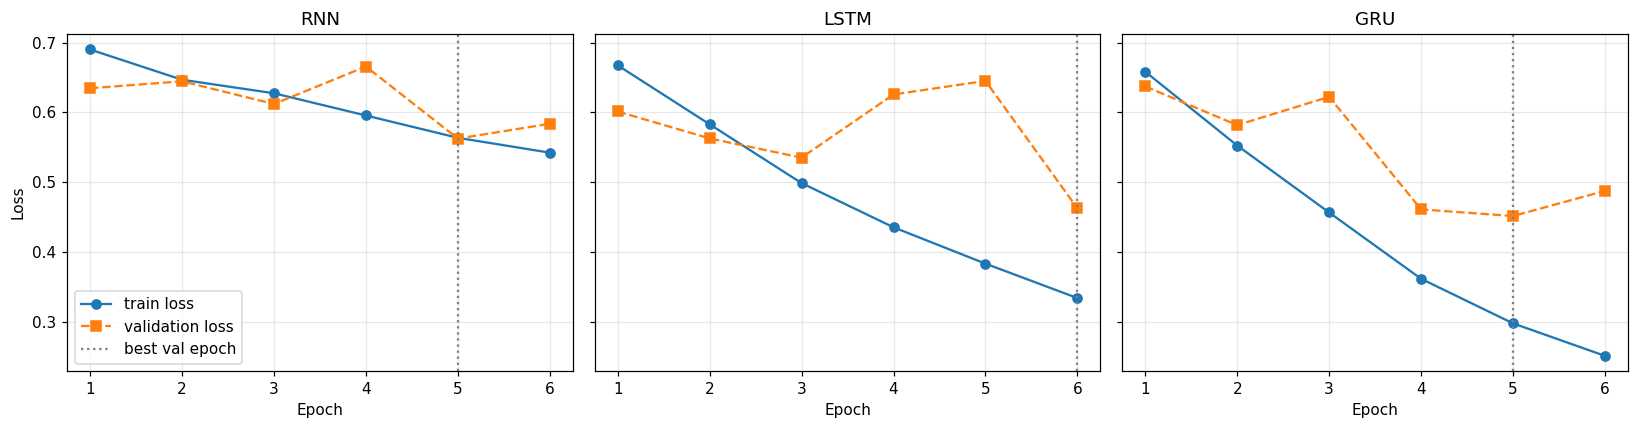

,epoch,train_loss,val_loss,val_acc,grad_norm,model
0,1,0.6900,0.6347,0.6500,0.8059,RNN
1,2,0.6468,0.6446,0.6570,1.7580,RNN
2,3,0.6275,0.6121,0.6905,1.0617,RNN
3,4,0.5957,0.6657,0.6500,1.4761,RNN
4,5,0.5638,0.5627,0.7390,1.1733,RNN
5,6,0.5426,0.5838,0.7200,4.4636,RNN


,epoch,train_loss,val_loss,val_acc,grad_norm,model
0,1,0.6674,0.6014,0.6965,0.3798,LSTM
1,2,0.5832,0.5629,0.7425,1.0099,LSTM
2,3,0.4991,0.5355,0.7595,1.3203,LSTM
3,4,0.4359,0.6258,0.7600,1.1401,LSTM
4,5,0.3839,0.6451,0.7610,1.2252,LSTM
5,6,0.3347,0.4630,0.8190,1.2326,LSTM


,epoch,train_loss,val_loss,val_acc,grad_norm,model
0,1,0.6583,0.6373,0.6600,0.6337,GRU
1,2,0.5528,0.5820,0.7450,1.4499,GRU
2,3,0.4570,0.6224,0.7570,1.1410,GRU
3,4,0.3623,0.4615,0.8235,1.1265,GRU
4,5,0.2986,0.4520,0.8280,1.0458,GRU
5,6,0.2521,0.4880,0.8460,1.0135,GRU


In [30]:
# Learning curves

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, a in zip(axes, ARCHS):
    h = exp4_runs[a][0]["history"]
    ax.plot(h["epoch"], h["train_loss"], "o-", label="train loss")
    ax.plot(h["epoch"], h["val_loss"], "s--", label="validation loss")
    ax.axvline(exp4_runs[a][0]["best_epoch"], color="gray", ls=":", label="best val epoch")
    ax.set_title(a); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Loss"); axes[0].legend()
plt.tight_layout()
plt.savefig("learning_curves.png", bbox_inches="tight")
plt.show()

for a in ARCHS:
    display(exp4_runs[a][0]["history"].round(4).assign(model=a))

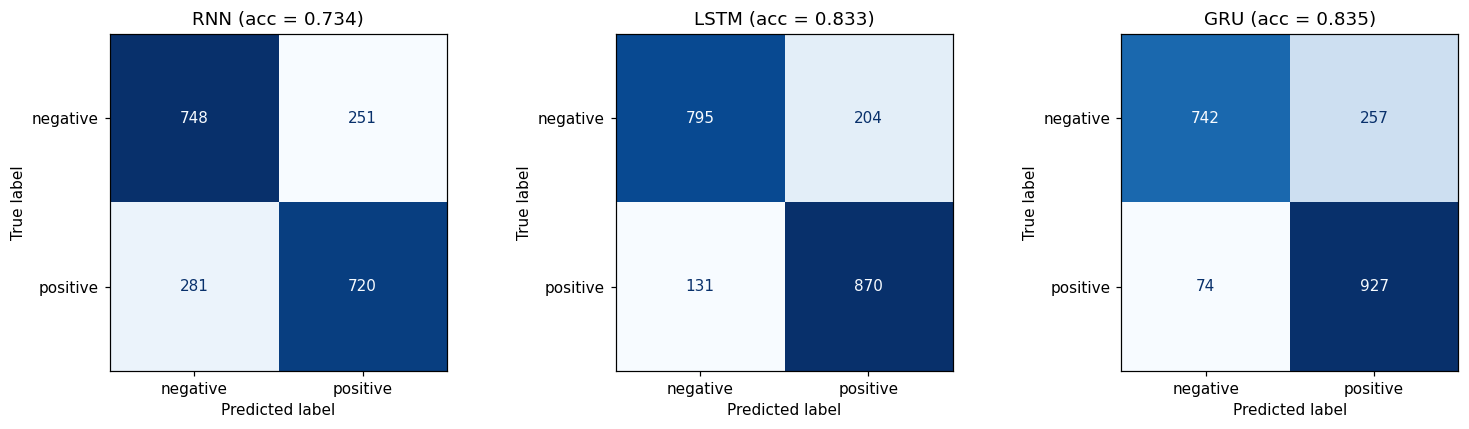

 RNN 
              precision    recall  f1-score   support

    negative     0.7269    0.7487    0.7377       999
    positive     0.7415    0.7193    0.7302      1001

    accuracy                         0.7340      2000
   macro avg     0.7342    0.7340    0.7339      2000
weighted avg     0.7342    0.7340    0.7339      2000

 LSTM 
              precision    recall  f1-score   support

    negative     0.8585    0.7958    0.8260       999
    positive     0.8101    0.8691    0.8386      1001

    accuracy                         0.8325      2000
   macro avg     0.8343    0.8325    0.8323      2000
weighted avg     0.8343    0.8325    0.8323      2000

 GRU 
              precision    recall  f1-score   support

    negative     0.9093    0.7427    0.8176       999
    positive     0.7829    0.9261    0.8485      1001

    accuracy                         0.8345      2000
   macro avg     0.8461    0.8344    0.8331      2000
weighted avg     0.8461    0.8345    0.8331      2000



In [54]:
# confusion matrix

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, a in zip(axes, ARCHS):
    r = exp4_runs[a][0]
    cm = confusion_matrix(r["y_true"], r["y_pred"])
    ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(f"{a} (acc = {r['accuracy']:.3f})")
plt.tight_layout()
plt.savefig("confusion_matrix.png", bbox_inches="tight")
plt.show()

for a in ARCHS:
    r = exp4_runs[a][0]
    print(f" {a} ")
    print(classification_report(r["y_true"], r["y_pred"], target_names=["negative", "positive"], digits=4))

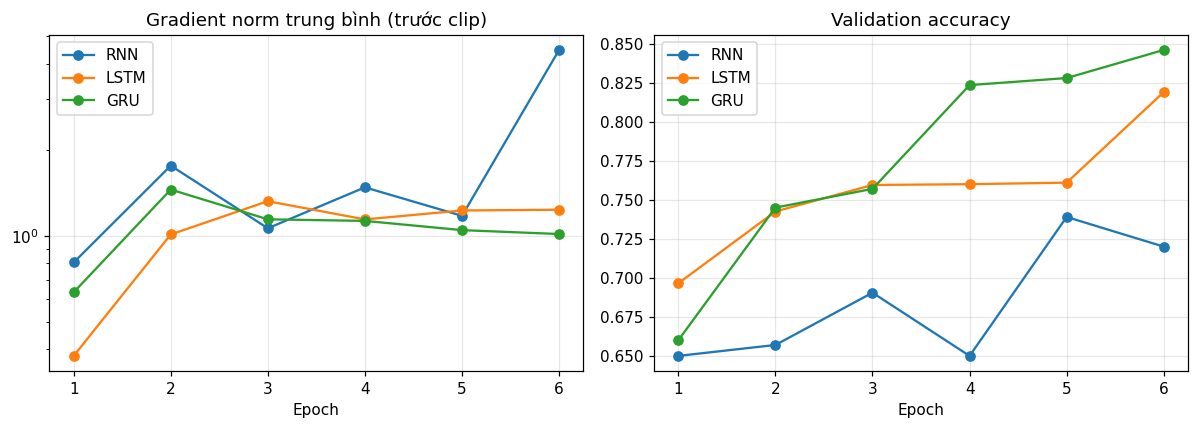

,Parameters,Training time (s),F1,F1 / 1M params
Model,,,,
RNN,2593153,645.6,0.7302,0.282
LSTM,2692225,2145.7,0.8386,0.311
GRU,2659201,3148.2,0.8485,0.319


In [32]:
# Chi phí tính toán, độ ổn định gradient và độ chính xác

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for a in ARCHS:
    h = exp4_runs[a][0]["history"]
    axes[0].plot(h["epoch"], h["grad_norm"], "o-", label=a)
    axes[1].plot(h["epoch"], h["val_acc"], "o-", label=a)
axes[0].set_title("Gradient norm trung bình (trước clip)"); axes[0].set_xlabel("Epoch"); axes[0].set_yscale("log")
axes[1].set_title("Validation accuracy"); axes[1].set_xlabel("Epoch")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

cost = exp4_table.set_index("Model")[["Parameters", "Training time (s)", "F1"]]
cost["F1 / 1M params"] = (cost["F1"] / (cost["Parameters"] / 1e6)).round(3)
display(cost)

### Experiement 5: Sequence length

In [33]:
EXP5_ARCHS = ["RNN", "LSTM"]
exp5_runs = {a: [get_or_run(a, L, SEED, experiment="exp2_exp5_length", notes="sequence length sweep")
                 for L in LENGTH_GRID] for a in EXP5_ARCHS}

[RNN  L= 50] epoch 1/6 | train 0.7043 | val 0.6975 | val acc 0.5180 | grad norm 0.66
[RNN  L= 50] epoch 2/6 | train 0.6831 | val 0.6577 | val acc 0.6275 | grad norm 0.68
[RNN  L= 50] epoch 3/6 | train 0.6664 | val 0.6798 | val acc 0.5925 | grad norm 1.03
[RNN  L= 50] epoch 4/6 | train 0.6472 | val 0.6727 | val acc 0.6300 | grad norm 0.96
[RNN  L= 50] epoch 5/6 | train 0.6192 | val 0.6382 | val acc 0.6615 | grad norm 1.18
[RNN  L= 50] epoch 6/6 | train 0.5928 | val 0.6633 | val acc 0.6735 | grad norm 1.16
[RNN  L=100] epoch 1/6 | train 0.7007 | val 0.6943 | val acc 0.5240 | grad norm 1.30
[RNN  L=100] epoch 2/6 | train 0.6797 | val 0.6848 | val acc 0.5695 | grad norm 0.72
[RNN  L=100] epoch 3/6 | train 0.6517 | val 0.6496 | val acc 0.6470 | grad norm 1.39
[RNN  L=100] epoch 4/6 | train 0.6302 | val 0.6355 | val acc 0.6580 | grad norm 0.98
[RNN  L=100] epoch 5/6 | train 0.6088 | val 0.6446 | val acc 0.6585 | grad norm 1.32
[RNN  L=100] epoch 6/6 | train 0.5951 | val 0.6257 | val acc 0.67

In [34]:
rows = []
for a in EXP5_ARCHS:
    for r in exp5_runs[a]:
        rows.append({
            "Model": a, "max_length": r["max_len"], "% tokens retained": round(r["pct_retained"], 1),
            "Training time (s)": round(r["train_time"], 1),
            "Time / epoch (s)": round(r["train_time"] / EPOCHS, 1),
            "Best val loss": round(r["best_val_loss"], 4), "Test F1": round(r["f1"], 4)})
exp5_df = pd.DataFrame(rows)
display(exp5_df)

,Model,max_length,% tokens retained,Training time (s),Time / epoch (s),Best val loss,Test F1
0,RNN,50,21.4,99.8,16.6,0.6382,0.6859
1,RNN,100,41.4,287.7,48.0,0.6257,0.7098
2,RNN,200,68.4,645.6,107.6,0.5627,0.7302
3,LSTM,50,21.4,401.8,67.0,0.5346,0.7519
4,LSTM,100,41.4,736.0,122.7,0.6020,0.7324
5,LSTM,200,68.4,2145.7,357.6,0.4630,0.8386


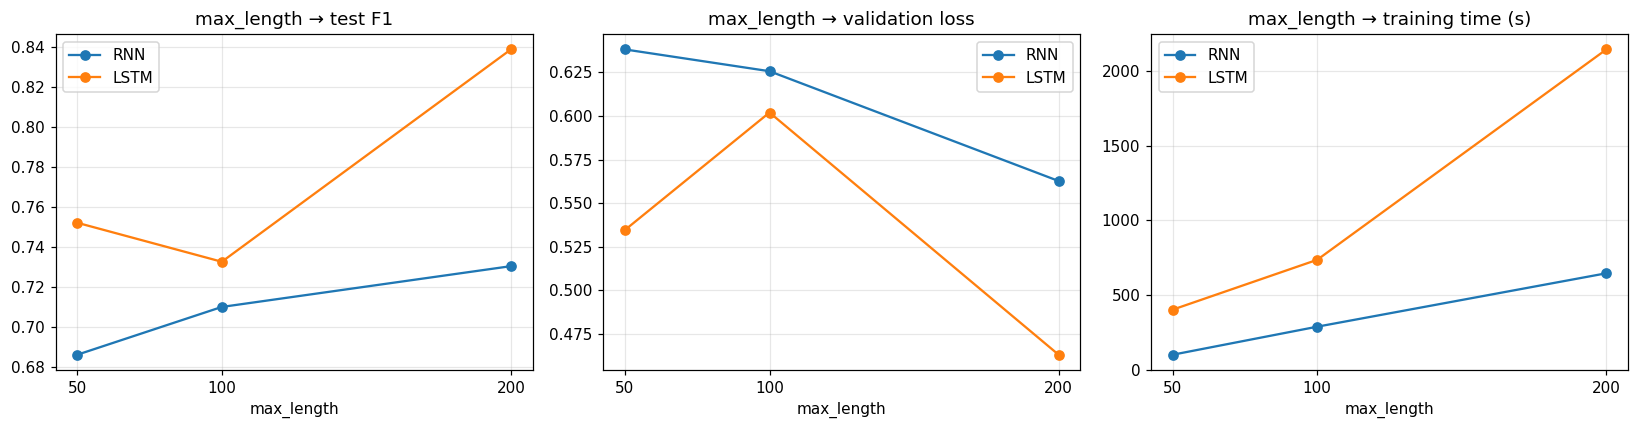

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for a in EXP5_ARCHS:
    d = exp5_df[exp5_df["Model"] == a]
    axes[0].plot(d["max_length"], d["Test F1"], "o-", label=a)
    axes[1].plot(d["max_length"], d["Best val loss"], "o-", label=a)
    axes[2].plot(d["max_length"], d["Training time (s)"], "o-", label=a)
axes[0].set_title("max_length → test F1")
axes[1].set_title("max_length → validation loss")
axes[2].set_title("max_length → training time (s)")
for ax in axes:
    ax.set_xlabel("max_length"); ax.set_xticks(LENGTH_GRID); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig("seq_length_effect.png", bbox_inches="tight")
plt.show()

### Experiment 6: Long-range dependency

In [36]:
models6 = {a: exp4_runs[a][0]["model"] for a in ARCHS}

examples = [
    "The movie was, despite many unnecessary scenes, ultimately excellent.",
    "The movie was, despite many unnecessary scenes, ultimately terrible.",
]
ex_df = pd.DataFrame({"Câu": examples})
for a in ARCHS:
    ex_df[f"P(pos) {a}"] = predict_proba(models6[a], examples).round(3)
display(ex_df)

,Câu,P(pos) RNN,P(pos) LSTM,P(pos) GRU
0,"The movie was, despite many unnecessary scenes...",0.708,0.769,0.65
1,"The movie was, despite many unnecessary scenes...",0.156,0.160,0.20


In [37]:
# - `begin` : `KEY + filler`
# - `middle`: `filler/2 + KEY + filler/2`
# - `end`   : `filler + KEY`

POS_KEYS = ["this movie is excellent", "i absolutely loved this film", "a wonderful and moving masterpiece",
            "truly one of the best movies i have ever seen", "the acting was brilliant and the story was great"]
NEG_KEYS = ["this movie is terrible", "i absolutely hated this film", "a boring and awful waste of time",
            "truly one of the worst movies i have ever seen", "the acting was awful and the story was bad"]
FILLER_POOL = [
    "the film was shot in several cities over the course of a year",
    "the story follows a family who moves to a small town",
    "there are a number of scenes set in an office and a school",
    "the cast includes many actors and the running time is about two hours",
    "most of the action takes place during one summer",
    "the director previously worked on television and short films",
    "the soundtrack uses both piano and guitar in many scenes",
    "a few characters appear only briefly in the middle of the film",
]
FILLER_TOKENS = [tok for s in FILLER_POOL for tok in tokenize(s)]


def filler(n, offset=0):
    return [FILLER_TOKENS[(offset + i) % len(FILLER_TOKENS)] for i in range(n)]


def build_sentence(key, position, n_filler):
    k = tokenize(key)
    if position == "begin":
        return k + filler(n_filler)
    if position == "end":
        return filler(n_filler) + k
    half = n_filler // 2
    return filler(half) + k + filler(n_filler - half, offset=half)


def eval_position(model, position, n_filler):
    toks, signs = [], []
    for key in POS_KEYS:
        toks.append(build_sentence(key, position, n_filler)); signs.append(+1)
    for key in NEG_KEYS:
        toks.append(build_sentence(key, position, n_filler)); signs.append(-1)
    assert max(len(t) for t in toks) <= MAX_LEN, "câu dài hơn MAX_LEN -> sẽ bị truncate, giảm n_filler"
    p = predict_proba_tokens(model, toks, MAX_LEN)
    signs = np.array(signs)
    acc = float((((p >= 0.5) * 2 - 1) == signs).mean())
    margin = float(((p - 0.5) * signs).mean())
    return acc, margin


N_FILLER = 100
pos_rows = []
for a in ARCHS:
    for position in ["begin", "middle", "end"]:
        acc, margin = eval_position(models6[a], position, N_FILLER)
        pos_rows.append({"Model": a, "Key position": position, "Accuracy": acc, "Margin": round(margin, 3)})
pos_df = pd.DataFrame(pos_rows)
display(pos_df.pivot(index="Model", columns="Key position", values=["Accuracy", "Margin"])
        .reindex(ARCHS)[[("Accuracy", p) for p in ["begin", "middle", "end"]] +
                        [("Margin", p) for p in ["begin", "middle", "end"]]])

Accuracy             Margin              
Key position    begin middle  end  begin middle    end
Model                                                 
RNN               0.5    0.5  0.8  0.000  0.000  0.197
LSTM              0.9    0.8  0.8  0.327  0.266  0.276
GRU               1.0    1.0  0.9  0.423  0.339  0.285

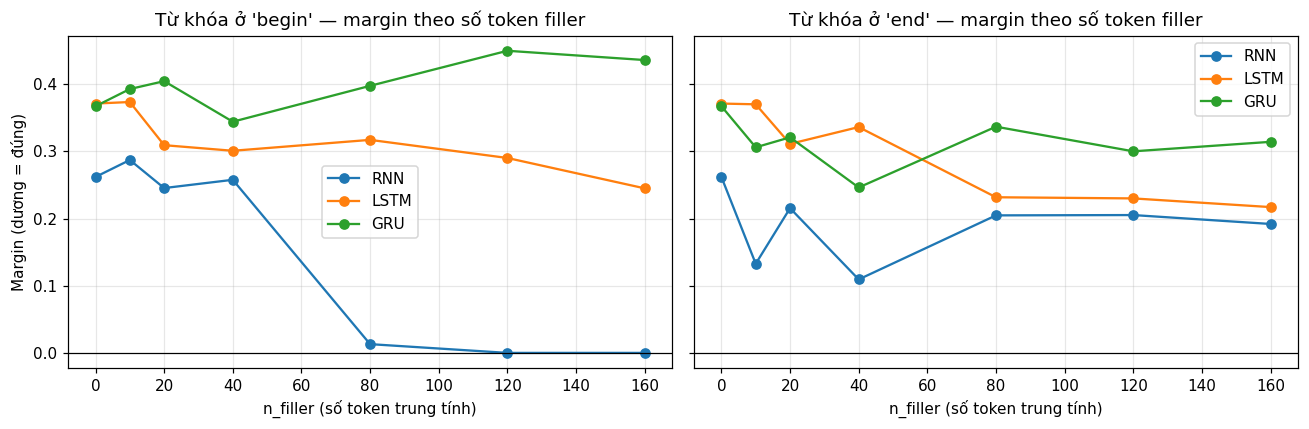

Model,RNN,LSTM,GRU
n_filler,,,
0,1.0,1.0,1.0
10,1.0,1.0,1.0
20,1.0,0.9,1.0
40,1.0,0.9,0.9
80,0.5,0.9,1.0
120,0.5,0.9,1.0
160,0.5,0.9,1.0


In [38]:
DISTANCES = [0, 10, 20, 40, 80, 120, 160]
dist_rows = []
for a in ARCHS:
    for n in DISTANCES:
        for position in ["begin", "end"]:
            acc, margin = eval_position(models6[a], position, n)
            dist_rows.append({"Model": a, "n_filler": n, "position": position, "accuracy": acc, "margin": margin})
dist_df = pd.DataFrame(dist_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, position in zip(axes, ["begin", "end"]):
    for a in ARCHS:
        d = dist_df[(dist_df["Model"] == a) & (dist_df["position"] == position)]
        ax.plot(d["n_filler"], d["margin"], "o-", label=a)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"Từ khóa ở '{position}' — margin theo số token filler")
    ax.set_xlabel("n_filler (số token trung tính)"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("Margin (dương = đúng)")
plt.tight_layout()
plt.savefig("long_range_dependency.png", bbox_inches="tight")
plt.show()

display(dist_df[dist_df["position"] == "begin"]
        .pivot(index="n_filler", columns="Model", values="accuracy")[ARCHS])

Số review test có độ dài >= MAX_LEN dùng cho phân tích gradient: 256


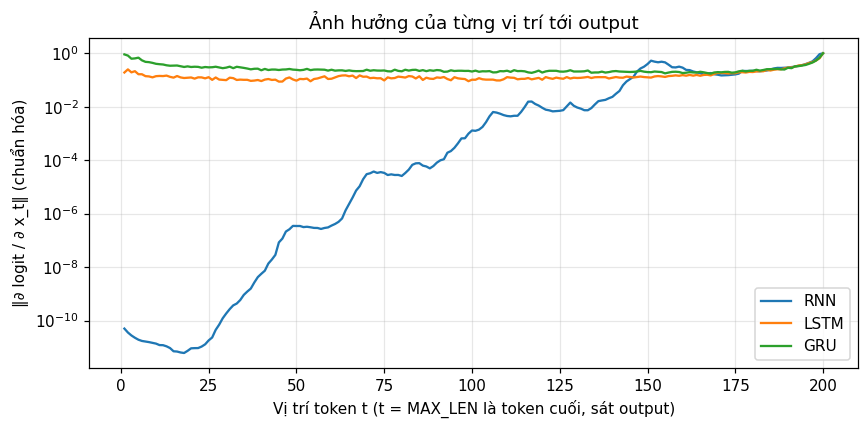

In [39]:
_, _, test_ds = get_datasets(MAX_LEN)
Xt, Lt, _ = test_ds.tensors
full_idx = (Lt == MAX_LEN).nonzero(as_tuple=True)[0][:256]
print(f"Số review test có độ dài >= MAX_LEN dùng cho phân tích gradient: {len(full_idx)}")


def gradient_norm_by_position(model, X, lengths):
    model.eval()
    with torch.backends.cudnn.flags(enabled=False):       # cuDNN RNN không cho backward ở eval mode
        emb = model.embedding(X.to(DEVICE)).detach().requires_grad_(True)
        logits = model.encode(emb, lengths)
        logits.sum().backward()
    g = emb.grad.norm(dim=-1).mean(0).cpu().numpy()       # (L,)
    return g / g.max()


fig, ax = plt.subplots(figsize=(8, 4))
for a in ARCHS:
    g = gradient_norm_by_position(models6[a], Xt[full_idx], Lt[full_idx])
    ax.semilogy(np.arange(1, MAX_LEN + 1), g, label=a)
ax.set_xlabel("Vị trí token t (t = MAX_LEN là token cuối, sát output)")
ax.set_ylabel("‖∂ logit / ∂ x_t‖ (chuẩn hóa)")
ax.set_title("Ảnh hưởng của từng vị trí tới output")
ax.grid(alpha=0.3, which="both"); ax.legend()
plt.tight_layout(); plt.savefig("gradient_by_position.png", bbox_inches="tight"); plt.show()

### 22. Evaluation

In [40]:
def confusion_counts(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    return tp, tn, fp, fn


def manual_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    return accuracy, precision, recall, f1


eval_inputs = {"TF-IDF + LR (baseline)": lr_pred}
for a in ARCHS:
    assert (exp4_runs[a][0]["y_true"] == y_test).all(), "thứ tự tập test không khớp"
    eval_inputs[a] = exp4_runs[a][0]["y_pred"]

eval_rows = []
for name, y_pred in eval_inputs.items():
    tp, tn, fp, fn = confusion_counts(y_test, y_pred)
    acc, prec, rec, f1 = manual_metrics(tp, tn, fp, fn)
    sk = compute_metrics(y_test, y_pred)
    matches = all(np.isclose(v, sk[k]) for k, v in
                  [("accuracy", acc), ("precision", prec), ("recall", rec), ("f1", f1)])
    eval_rows.append({"Model": name, "TP": tp, "TN": tn, "FP": fp, "FN": fn,
                      "Accuracy": round(acc, 4), "Precision": round(prec, 4),
                      "Recall": round(rec, 4), "F1": round(f1, 4), "Khớp sklearn": matches})
eval_df = pd.DataFrame(eval_rows)
display(eval_df)

,Model,TP,TN,FP,FN,Accuracy,Precision,Recall,F1,Khớp sklearn
0,TF-IDF + LR (baseline),903,877,122,98,0.8900,0.8810,0.9021,0.8914,True
1,RNN,720,748,251,281,0.7340,0.7415,0.7193,0.7302,True
2,LSTM,870,795,204,131,0.8325,0.8101,0.8691,0.8386,True
3,GRU,927,742,257,74,0.8345,0.7829,0.9261,0.8485,True


In [41]:
report_rows = [{
    "Model": "TF-IDF + LR (baseline)", "Parameters": int(lr_params),
    "Training time (s)": round(lr_time, 1), "Epochs": "—", "Sequence length": "— (bag of words)",
    "Vocabulary size": int(X_tr.shape[1])}]
for a in ARCHS:
    r = exp4_runs[a][0]
    report_rows.append({
        "Model": a, "Parameters": r["params"], "Training time (s)": round(r["train_time"], 1),
        "Epochs": f"{EPOCHS} (best = {r['best_epoch']})", "Sequence length": MAX_LEN,
        "Vocabulary size": VOCAB_SIZE})
report_df = pd.DataFrame(report_rows)
display(report_df)

full_eval = eval_df.merge(report_df, on="Model")
display(full_eval[["Model", "Accuracy", "Precision", "Recall", "F1", "Parameters",
                   "Training time (s)", "Epochs", "Sequence length", "Vocabulary size"]])

,Model,Parameters,Training time (s),Epochs,Sequence length,Vocabulary size
0,TF-IDF + LR (baseline),39355,2.5,—,— (bag of words),39354
1,RNN,2593153,645.6,6 (best = 5),200,20000
2,LSTM,2692225,2145.7,6 (best = 6),200,20000
3,GRU,2659201,3148.2,6 (best = 5),200,20000


,Model,Accuracy,Precision,Recall,F1,Parameters,Training time (s),Epochs,Sequence length,Vocabulary size
0,TF-IDF + LR (baseline),0.8900,0.8810,0.9021,0.8914,39355,2.5,—,— (bag of words),39354
1,RNN,0.7340,0.7415,0.7193,0.7302,2593153,645.6,6 (best = 5),200,20000
2,LSTM,0.8325,0.8101,0.8691,0.8386,2692225,2145.7,6 (best = 6),200,20000
3,GRU,0.8345,0.7829,0.9261,0.8485,2659201,3148.2,6 (best = 5),200,20000


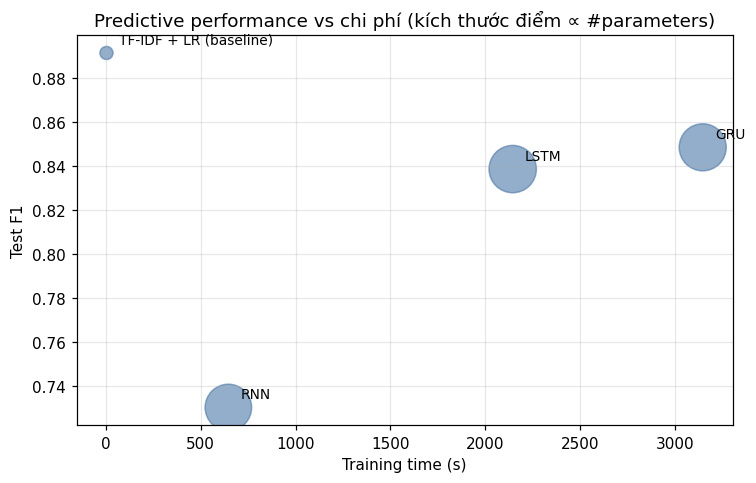

In [42]:
# Hiệu năng so với chi phí: F1 theo thời gian train; kích thước điểm tỉ lệ với số tham số
fig, ax = plt.subplots(figsize=(7, 4.5))
sizes = 60 + 900 * full_eval["Parameters"] / full_eval["Parameters"].max()
ax.scatter(full_eval["Training time (s)"], full_eval["F1"], s=sizes, alpha=0.6, c="#4C78A8")
for _, r in full_eval.iterrows():
    ax.annotate(r["Model"], (r["Training time (s)"], r["F1"]), textcoords="offset points",
                xytext=(8, 6), fontsize=9)
ax.set_xlabel("Training time (s)"); ax.set_ylabel("Test F1")
ax.set_title("Predictive performance vs chi phí (kích thước điểm ∝ #parameters)")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 23. Learning curves

In [43]:
lc_frames = []
for a in ARCHS:
    h = exp4_runs[a][0]["history"][["epoch", "train_loss", "val_loss"]].set_index("epoch")
    h.columns = pd.MultiIndex.from_product([[a], ["Train Loss", "Validation Loss"]])
    lc_frames.append(h)
lc_table = pd.concat(lc_frames, axis=1).round(4)
display(lc_table)

RNN                       LSTM                        GRU                
      Train Loss Validation Loss Train Loss Validation Loss Train Loss Validation Loss
epoch                                                                                 
1         0.6900          0.6347     0.6674          0.6014     0.6583          0.6373
2         0.6468          0.6446     0.5832          0.5629     0.5528          0.5820
3         0.6275          0.6121     0.4991          0.5355     0.4570          0.6224
4         0.5957          0.6657     0.4359          0.6258     0.3623          0.4615
5         0.5638          0.5627     0.3839          0.6451     0.2986          0.4520
6         0.5426          0.5838     0.3347          0.4630     0.2521          0.4880

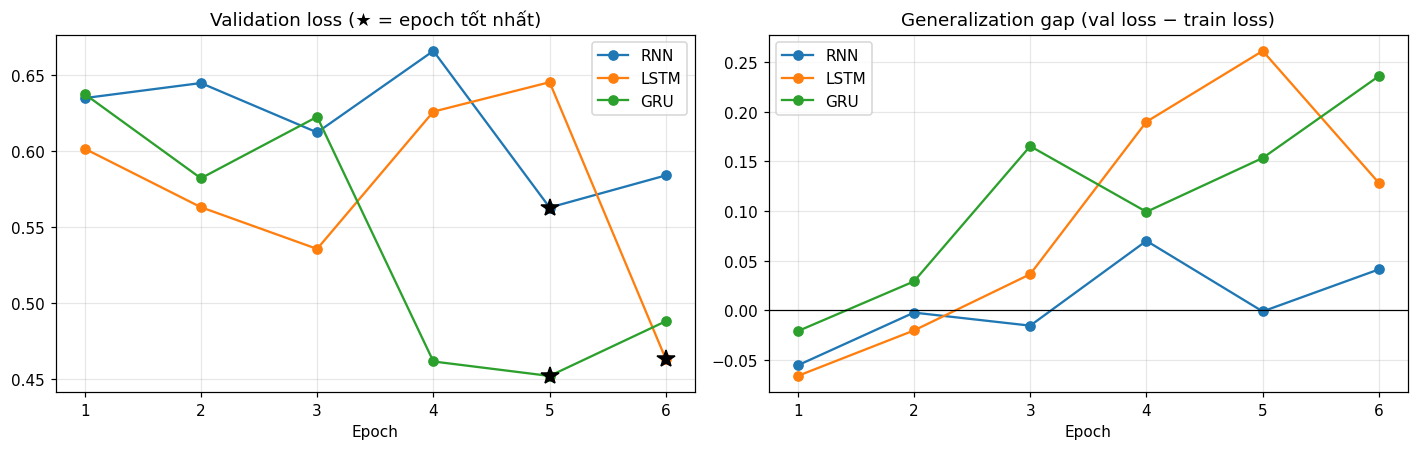

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for a in ARCHS:
    h = exp4_runs[a][0]["history"]
    axes[0].plot(h["epoch"], h["val_loss"], "o-", label=a)
    axes[1].plot(h["epoch"], h["val_loss"] - h["train_loss"], "o-", label=a)
    b = exp4_runs[a][0]["best_epoch"]
    axes[0].plot(b, h.loc[h["epoch"] == b, "val_loss"].iloc[0], "k*", ms=12)
axes[0].set_title("Validation loss (★ = epoch tốt nhất)")
axes[1].set_title("Generalization gap (val loss − train loss)")
axes[1].axhline(0, color="k", lw=0.8)
for ax in axes:
    ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig("learning_curves_compare.png", bbox_inches="tight")
plt.show()

In [45]:
# Chuẩn đoán overfitting

diag_rows = []
for a in ARCHS:
    h = exp4_runs[a][0]["history"].reset_index(drop=True)
    i_best = int(h["val_loss"].idxmin())
    best_ep = int(h.loc[i_best, "epoch"])
    min_val = float(h.loc[i_best, "val_loss"])
    final_val = float(h["val_loss"].iloc[-1])
    rise_pct = (final_val - min_val) / min_val * 100
    after = h[h["epoch"] > best_ep]
    train_still_down = len(after) > 0 and float(after["train_loss"].iloc[-1]) < float(h.loc[i_best, "train_loss"])
    flag = "Có dấu hiệu" if (len(after) > 0 and rise_pct > 2 and train_still_down) else "Chưa thấy rõ"
    diag_rows.append({
        "Model": a, "Best epoch": best_ep, "Min val loss": round(min_val, 4),
        "Final val loss": round(final_val, 4), "Final vs min (%)": round(rise_pct, 1),
        "Train loss @best": round(float(h.loc[i_best, "train_loss"]), 4),
        "Train loss @final": round(float(h["train_loss"].iloc[-1]), 4),
        "Epochs sau best": len(after), "Overfitting?": flag})
display(pd.DataFrame(diag_rows))

,Model,Best epoch,Min val loss,Final val loss,Final vs min (%),Train loss @best,Train loss @final,Epochs sau best,Overfitting?
0,RNN,5,0.5627,0.5838,3.8,0.5638,0.5426,1,Có dấu hiệu
1,LSTM,6,0.4630,0.4630,0.0,0.3347,0.3347,0,Chưa thấy rõ
2,GRU,5,0.4520,0.4880,8.0,0.2986,0.2521,1,Có dấu hiệu


,Source,Model,Representation,Accuracy,Precision,Recall,F1,Training time (s),Vocabulary,ΔF1 vs LAB04 TF-IDF+LR
0,LAB 04,Logistic Regression,TF-IDF (unigram),0.8998,0.8940,0.9080,0.9009,13.86,54511,0.0000
1,LAB 04,Logistic Regression,Avg Word2Vec,0.8506,0.8468,0.8574,0.8521,55.60,56757,-0.0488
2,LAB 04,Linear SVM,TF-IDF (unigram),0.8996,0.8955,0.9056,0.9005,NaN,54511,-0.0004
3,LAB 04,Logistic Regression,TF-IDF (uni+bigram),0.9018,0.8922,0.9148,0.9034,24.62,614975,0.0025
4,LAB 05,RNN,Embedding (learned),0.7340,0.7415,0.7193,0.7302,645.60,20000,-0.1707
5,LAB 05,LSTM,Embedding (learned),0.8325,0.8101,0.8691,0.8386,2145.70,20000,-0.0623
6,LAB 05,GRU,Embedding (learned),0.8345,0.7829,0.9261,0.8485,3148.20,20000,-0.0524


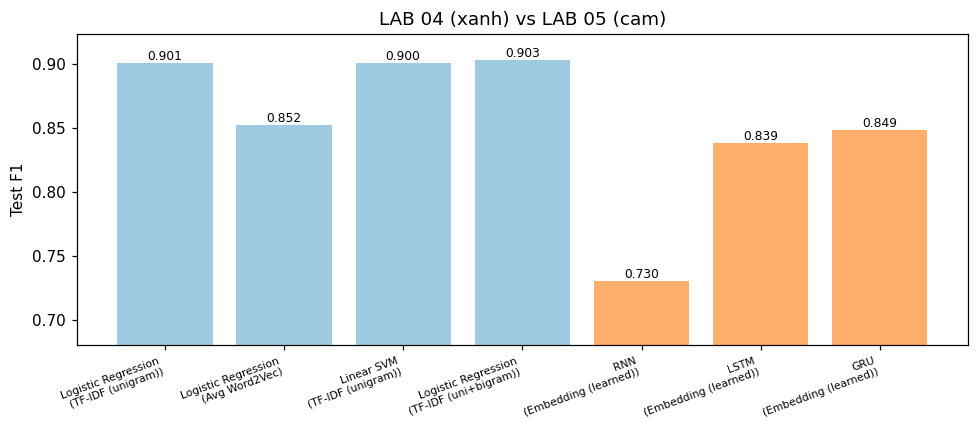

In [46]:
# Lab 4 vs lab 5

LAB04_ROWS = [
    {"Source": "LAB 04", "Model": "Logistic Regression", "Representation": "TF-IDF (unigram)",
     "Accuracy": 0.8998, "Precision": 0.8940, "Recall": 0.9080, "F1": 0.9009,
     "Training time (s)": 13.86, "Vocabulary": 54511},
    {"Source": "LAB 04", "Model": "Logistic Regression", "Representation": "Avg Word2Vec",
     "Accuracy": 0.8506, "Precision": 0.8468, "Recall": 0.8574, "F1": 0.8521,
     "Training time (s)": 55.6, "Vocabulary": 56757},
    {"Source": "LAB 04", "Model": "Linear SVM", "Representation": "TF-IDF (unigram)",
     "Accuracy": 0.8996, "Precision": 0.8955, "Recall": 0.9056, "F1": 0.9005,
     "Training time (s)": None, "Vocabulary": 54511},
    {"Source": "LAB 04", "Model": "Logistic Regression", "Representation": "TF-IDF (uni+bigram)",
     "Accuracy": 0.9018, "Precision": 0.8922, "Recall": 0.9148, "F1": 0.9034,
     "Training time (s)": 24.62, "Vocabulary": 614975},
]
lab04_df = pd.DataFrame(LAB04_ROWS)
LAB04_BASE_F1 = 0.9009   # TF-IDF + LR của LAB 04

lab05_rows = []
for a in ARCHS:
    r = exp4_runs[a][0]
    lab05_rows.append({
        "Source": "LAB 05", "Model": a, "Representation": "Embedding (learned)",
        "Accuracy": round(r["accuracy"], 4), "Precision": round(r["precision"], 4),
        "Recall": round(r["recall"], 4), "F1": round(r["f1"], 4),
        "Training time (s)": round(r["train_time"], 1), "Vocabulary": VOCAB_SIZE})
lab05_df = pd.DataFrame(lab05_rows)

compare_df = pd.concat([lab04_df, lab05_df], ignore_index=True)
compare_df["ΔF1 vs LAB04 TF-IDF+LR"] = (compare_df["F1"] - LAB04_BASE_F1).round(4)
display(compare_df)

fig, ax = plt.subplots(figsize=(9, 4))
labels = compare_df["Model"] + "\n(" + compare_df["Representation"] + ")"
colors = ["#9ecae1" if s == "LAB 04" else "#fdae6b" for s in compare_df["Source"]]
ax.bar(range(len(compare_df)), compare_df["F1"], color=colors)
ax.set_xticks(range(len(compare_df))); ax.set_xticklabels(labels, fontsize=7, rotation=20, ha="right")
ax.set_ylim(max(0.0, compare_df["F1"].min() - 0.05), min(1.0, compare_df["F1"].max() + 0.02))
ax.set_ylabel("Test F1"); ax.set_title("LAB 04 (xanh) vs LAB 05 (cam)")
for i, v in enumerate(compare_df["F1"]):
    ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

In [47]:
S1, S2 = "this movie is good", "this movie is not good"

# LAB 04 
order_rows = [
    {"Source": "LAB 04", "Model": "TF-IDF (unigram) + LR", "P(pos|S1)": 0.8593, "P(pos|S2)": 0.5668},
    {"Source": "LAB 04", "Model": "Avg Word2Vec + LR", "P(pos|S1)": 0.9882, "P(pos|S2)": 0.5073},
    {"Source": "LAB 04", "Model": "TF-IDF (uni+bigram) + LR", "P(pos|S1)": 0.8264, "P(pos|S2)": 0.1120},
]
# LAB 05
for a in ARCHS:
    p = predict_proba(exp4_runs[a][0]["model"], [S1, S2])
    order_rows.append({"Source": "LAB 05", "Model": a, "P(pos|S1)": float(p[0]), "P(pos|S2)": float(p[1])})

order_df = pd.DataFrame(order_rows)
order_df["Giảm (S1 − S2)"] = order_df["P(pos|S1)"] - order_df["P(pos|S2)"]
display(order_df.round(4))
print("LAB 04: cosine(vector S1, vector S2) của Avg Word2Vec = 0.9581")

,Source,Model,P(pos|S1),P(pos|S2),Giảm (S1 − S2)
0,LAB 04,TF-IDF (unigram) + LR,0.8593,0.5668,0.2925
1,LAB 04,Avg Word2Vec + LR,0.9882,0.5073,0.4809
2,LAB 04,TF-IDF (uni+bigram) + LR,0.8264,0.1120,0.7144
3,LAB 05,RNN,0.5736,0.5529,0.0207
4,LAB 05,LSTM,0.6254,0.3581,0.2673
5,LAB 05,GRU,0.5026,0.2563,0.2463


LAB 04: cosine(vector S1, vector S2) của Avg Word2Vec = 0.9581


### 26. Application

In [48]:
APP_CANDIDATES = ["LSTM", "GRU"]
APP_ARCH = max(APP_CANDIDATES, key=lambda a: exp4_runs[a][0]["f1"])   
app_model = exp4_runs[APP_ARCH][0]["model"]
print("Model dùng cho ứng dụng:", APP_ARCH,
      "| test F1 =", round(exp4_runs[APP_ARCH][0]["f1"], 4), "| max_length =", MAX_LEN)


def predict_sentiment(review, model=None, max_len=MAX_LEN, threshold=0.5):
    # Raw review -> token -> id -> pad/truncate -> model -> nhãn + xác suất.
    model = model or app_model
    tokens = tokenize(review)
    ids = encode(tokens)
    if len(ids) == 0:
        raise ValueError("Review không chứa token hợp lệ.")
    padded, length = pad_or_truncate(ids, max_len)
    x = torch.tensor([padded], device=DEVICE)
    lengths = torch.tensor([length])
    model.eval()
    with torch.no_grad():
        prob = torch.sigmoid(model(x, lengths)).item()
    return {"label": "positive" if prob >= threshold else "negative", "prob": prob,
            "n_tokens": len(tokens), "truncated": len(tokens) > max_len,
            "n_unk": sum(i == UNK_ID for i in ids)}


result = predict_sentiment("I really enjoyed this movie.")
print(f"{result['label'].capitalize()}")
print(f"Probability: {result['prob']:.4f}")
print(result)

Model dùng cho ứng dụng: GRU | test F1 = 0.8485 | max_length = 200
Positive
Probability: 0.8744
{'label': 'positive', 'prob': 0.8744021058082581, 'n_tokens': 5, 'truncated': False, 'n_unk': 0}


In [49]:
demo_review = "I really enjoyed this movie."
tokens = tokenize(demo_review)
ids = encode(tokens)
padded, length = pad_or_truncate(ids, MAX_LEN)

print("1) Raw review:", demo_review)
print("2) Tokenizer:", tokens)
print("3) Vocabulary:", [(t, stoi.get(t, UNK_ID), "<UNK>" if t not in stoi else "") for t in tokens])
print("4) Token IDs:", ids)
print(f"5) Padding: {length} token thật + {MAX_LEN - length} <PAD>  ->  {padded[:12]} ... (độ dài {len(padded)})")

app_model.eval()
with torch.no_grad():
    x = torch.tensor([padded], device=DEVICE)
    l = torch.tensor([length])
    emb = app_model.embed(x)
    print("6) Embedding     : shape", tuple(emb.shape), "= (batch, max_length, embedding_dim)")
    packed = pack_padded_sequence(emb, l, batch_first=True, enforce_sorted=False)
    _, h = app_model.rnn(packed)
    if isinstance(h, tuple):
        h = h[0]
    h_T = h[-1]
    print(f"7) {APP_ARCH:4s} -> h_T  : shape", tuple(h_T.shape), "(chỉ đọc", length, "token thật, bỏ qua <PAD>)")
    logit = app_model.fc(h_T).squeeze(-1)
    prob = torch.sigmoid(logit).item()
    print(f"8) Linear        : logit = {logit.item():.4f}  ->  sigmoid = {prob:.4f}")
print("9) Sentiment     :", "Positive" if prob >= 0.5 else "Negative", f"| Probability = {prob:.4f}")

1) Raw review: I really enjoyed this movie.
2) Tokenizer: ['i', 'really', 'enjoyed', 'this', 'movie']
3) Vocabulary: [('i', 10, ''), ('really', 63, ''), ('enjoyed', 515, ''), ('this', 11, ''), ('movie', 17, '')]
4) Token IDs: [10, 63, 515, 11, 17]
5) Padding: 5 token thật + 195 <PAD>  ->  [10, 63, 515, 11, 17, 0, 0, 0, 0, 0, 0, 0] ... (độ dài 200)
6) Embedding     : shape (1, 200, 128) = (batch, max_length, embedding_dim)
7) GRU  -> h_T  : shape (1, 128) (chỉ đọc 5 token thật, bỏ qua <PAD>)
8) Linear        : logit = 1.9405  ->  sigmoid = 0.8744
9) Sentiment     : Positive | Probability = 0.8744


In [50]:
# Thử các loại review 

ID2LABEL = {v: k for k, v in LABEL2ID.items()}

LONG_REVIEW = (
    "I went into this film with very low expectations. The trailer looked messy, the first twenty minutes are slow, "
    "and several of the early scenes feel pointless and badly edited. The supporting characters are thin, the dialogue "
    "is clumsy in places, and for a long stretch I honestly considered leaving the theater. But then the story slowly "
    "finds its footing. The lead performance becomes more subtle and moving, the music grows into something special, "
    "and the final half hour is beautifully shot and genuinely emotional. By the time the credits rolled I was "
    "completely won over, and I would happily watch it again."
)

# một review thật, dài hơn MAX_LEN để thấy truncation
_long_mask = df_test["length"] > MAX_LEN + 100
real_long = df_test[_long_mask].iloc[0] if _long_mask.any() else df_test.sort_values("length").iloc[-1]

LAB04_APP = {   # P(positive) của pipeline TF-IDF uni+bigram + LR ở LAB 04
    "I love this movie, the story and the acting are wonderful.": 0.925,
    "This movie is terrible and boring.": 0.005,
    "this movie is not good": 0.112,
    "I do not like this movie": 0.244,
    "Great, another two hours of my life I will never get back.": 0.657,
}

app_cases = [
    ("short", "I really enjoyed this movie.", "positive"),
    ("short", "I love this movie, the story and the acting are wonderful.", "positive"),
    ("short", "This movie is terrible and boring.", "negative"),
    ("negation", "this movie is not good", "negative"),
    ("negation", "I do not like this movie", "negative"),
    ("negation", "I did not like this movie at all.", "negative"),
    ("contrast", "I thought the movie would be terrible, but it was surprisingly good.", "positive"),
    ("contrast", "I expected the movie to be bad, but it was actually wonderful.", "positive"),
    ("contrast (đảo chiều)", "I expected a masterpiece, but it was a boring mess.", "negative"),
    ("sarcasm", "Great, another two hours of my life I will never get back.", "negative"),
    ("long (viết tay, kết luận ở cuối)", LONG_REVIEW, "positive"),
    ("long (review thật, bị truncate)", real_long[TEXT_COL], ID2LABEL[int(real_long["label"])]),
]

rows = []
for category, review, expected in app_cases:
    row = {"Category": category,
           "Review": (review[:70] + "...") if len(review) > 70 else review,
           "Expected": expected}
    info = None
    for a in APP_CANDIDATES:
        info = predict_sentiment(review, exp4_runs[a][0]["model"])
        row[f"P(pos) {a}"] = round(info["prob"], 3)
        row[f"Đúng? {a}"] = info["label"] == expected
    row["n_tokens"], row["truncated"] = info["n_tokens"], info["truncated"]
    row["LAB04 P(pos)"] = LAB04_APP.get(review)
    rows.append(row)

pd.set_option("display.max_colwidth", 80)
app_df = pd.DataFrame(rows)
display(app_df)
for a in APP_CANDIDATES:
    print(f"{a}: đúng {int(app_df[f'Đúng? {a}'].sum())}/{len(app_df)} ca (chỉ là ví dụ minh họa, không thay thế test set)")

,Category,Review,Expected,P(pos) LSTM,Đúng? LSTM,P(pos) GRU,Đúng? GRU,n_tokens,truncated,LAB04 P(pos)
0,short,I really enjoyed this movie.,positive,0.789,True,0.874,True,5,False,NaN
1,short,"I love this movie, the story and the acting are wonderful.",positive,0.890,True,0.901,True,11,False,0.925
2,short,This movie is terrible and boring.,negative,0.033,True,0.013,True,6,False,0.005
3,negation,this movie is not good,negative,0.358,True,0.256,True,5,False,0.112
4,negation,I do not like this movie,negative,0.241,True,0.345,True,6,False,0.244
5,negation,I did not like this movie at all.,negative,0.346,True,0.253,True,8,False,NaN
6,contrast,"I thought the movie would be terrible, but it was surprisingly good.",positive,0.437,False,0.486,False,12,False,NaN
7,contrast,"I expected the movie to be bad, but it was actually wonderful.",positive,0.503,True,0.339,False,12,False,NaN
8,contrast (đảo chiều),"I expected a masterpiece, but it was a boring mess.",negative,0.071,True,0.092,True,10,False,NaN
9,sarcasm,"Great, another two hours of my life I will never get back.",negative,0.917,False,0.955,False,12,False,0.657


LSTM: đúng 9/12 ca (chỉ là ví dụ minh họa, không thay thế test set)
GRU: đúng 8/12 ca (chỉ là ví dụ minh họa, không thay thế test set)


Review: I thought the movie would be terrible, but it was surprisingly good.
P(positive) = 0.486 -> negative
  Đẩy về POSITIVE: [('surprisingly', 0.21), ('it', 0.122), ('i', 0.097), ('was', 0.081)]
  Đẩy về NEGATIVE: [('terrible', -0.302), ('movie', -0.041)]


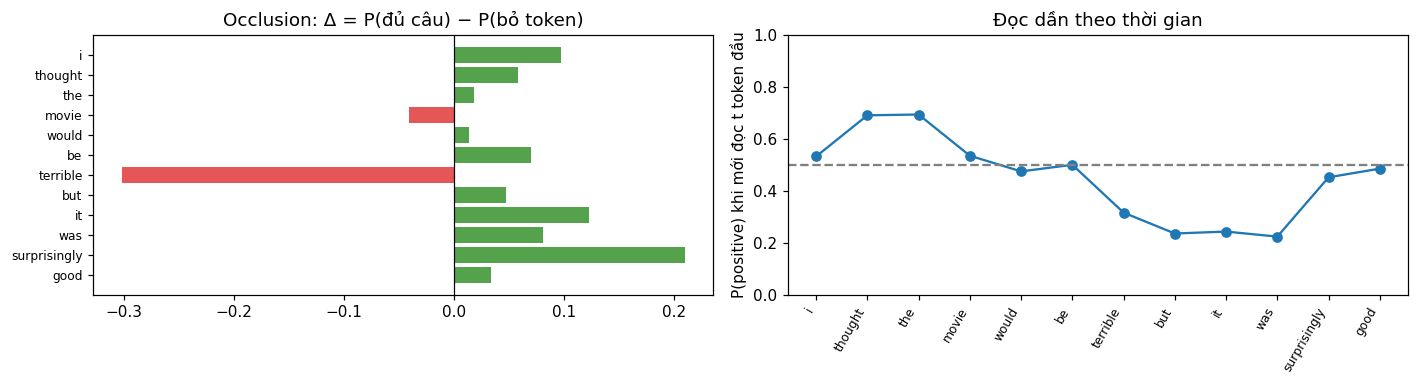


Review: I did not like this movie at all.
P(positive) = 0.253 -> negative
  Đẩy về POSITIVE: [('i', 0.097), ('all', 0.028), ('like', 0.015)]
  Đẩy về NEGATIVE: [('at', -0.207), ('movie', -0.068), ('this', -0.064), ('not', -0.063)]


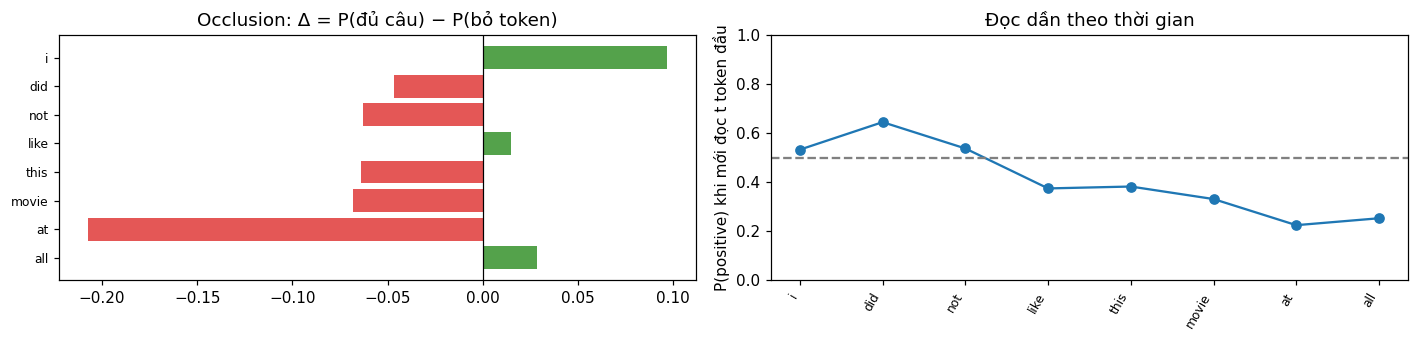


Review: I expected a masterpiece, but it was a boring mess.
P(positive) = 0.092 -> negative
  Đẩy về POSITIVE: [('it', 0.047), ('masterpiece', 0.034), ('a', 0.025), ('i', 0.022)]
  Đẩy về NEGATIVE: [('boring', -0.3), ('mess', -0.099), ('but', -0.062), ('expected', -0.041)]


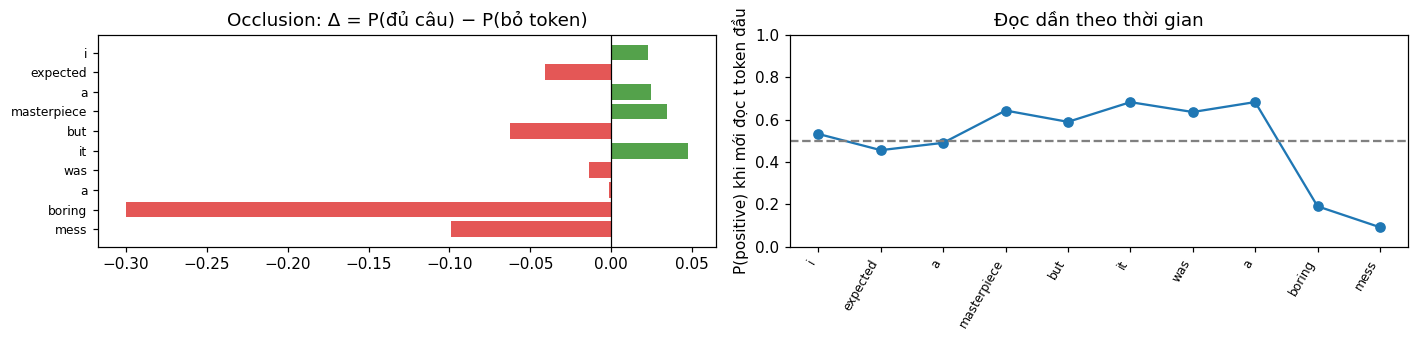

In [51]:
# Từ hoặc đoạn context ảnh hưởng đến prediction

def explain(review, model=None, max_len=MAX_LEN, top_k=4, plot=True):
    model = model or app_model
    tokens = tokenize(review)[:max_len]
    n = len(tokens)
    base = float(predict_proba_tokens(model, [tokens], max_len)[0])
    occluded = predict_proba_tokens(model, [tokens[:i] + tokens[i + 1:] for i in range(n)], max_len)
    delta = base - occluded
    prefix = predict_proba_tokens(model, [tokens[:t] for t in range(1, n + 1)], max_len)

    order = np.argsort(delta)
    print(f"Review: {review[:110]}{'...' if len(review) > 110 else ''}")
    print(f"P(positive) = {base:.3f} -> {'positive' if base >= 0.5 else 'negative'}")
    print("  Đẩy về POSITIVE:", [(tokens[i], round(float(delta[i]), 3)) for i in order[::-1][:top_k] if delta[i] > 0])
    print("  Đẩy về NEGATIVE:", [(tokens[i], round(float(delta[i]), 3)) for i in order[:top_k] if delta[i] < 0])

    if plot and n <= 40:
        fig, axes = plt.subplots(1, 2, figsize=(13, max(3.2, 0.3 * n)))
        axes[0].barh(range(n), delta, color=["#54A24B" if d > 0 else "#E45756" for d in delta])
        axes[0].set_yticks(range(n)); axes[0].set_yticklabels(tokens, fontsize=8); axes[0].invert_yaxis()
        axes[0].axvline(0, color="k", lw=0.8)
        axes[0].set_title("Occlusion: Δ = P(đủ câu) − P(bỏ token)")
        axes[1].plot(range(1, n + 1), prefix, "o-")
        axes[1].axhline(0.5, color="gray", ls="--")
        axes[1].set_xticks(range(1, n + 1)); axes[1].set_xticklabels(tokens, rotation=60, ha="right", fontsize=8)
        axes[1].set_ylim(0, 1); axes[1].set_ylabel("P(positive) khi mới đọc t token đầu")
        axes[1].set_title("Đọc dần theo thời gian")
        plt.tight_layout(); plt.show()
    return delta, prefix


for text in ["I thought the movie would be terrible, but it was surprisingly good.",
             "I did not like this movie at all.",
             "I expected a masterpiece, but it was a boring mess."]:
    explain(text)
    print()

Negative
Probability: 0.1194  (n_tokens = 20, <UNK> = 0, truncated = False)
Review: The plot was predictable and slow, but the acting was so good that I did not want it to end.
P(positive) = 0.119 -> negative
  Đẩy về POSITIVE: [('it', 0.032), ('end', 0.03), ('good', 0.027), ('and', 0.021)]
  Đẩy về NEGATIVE: [('predictable', -0.277), ('plot', -0.12), ('acting', -0.058), ('was', -0.053)]


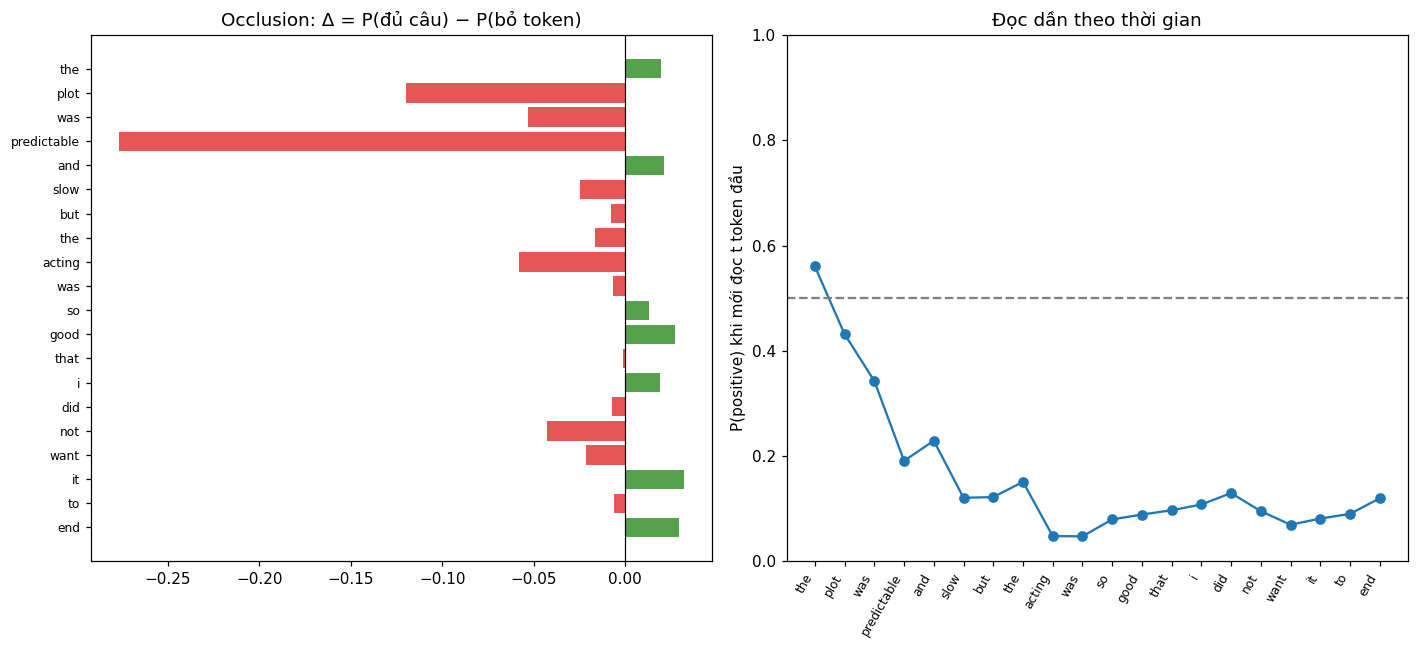

In [52]:
my_review = "The plot was predictable and slow, but the acting was so good that I did not want it to end."

res = predict_sentiment(my_review)
print(f"{res['label'].capitalize()}")
print(f"Probability: {res['prob']:.4f}  (n_tokens = {res['n_tokens']}, <UNK> = {res['n_unk']}, truncated = {res['truncated']})")
_ = explain(my_review)

In [53]:
_r = exp4_runs[APP_ARCH][0]
log_result(
    experiment="application", model=APP_ARCH, representation="Embedding (learned)",
    max_length=MAX_LEN, pct_tokens_retained=round(_r["pct_retained"], 2), vocab_size=VOCAB_SIZE,
    embedding_dim=EMB_DIM, hidden_size=HIDDEN_SIZE, params=_r["params"], rnn_params=_r["rnn_params"],
    epochs_run=EPOCHS, best_epoch=_r["best_epoch"], train_time_sec=round(_r["train_time"], 2),
    best_val_loss=round(_r["best_val_loss"], 5), accuracy=round(_r["accuracy"], 5),
    precision=round(_r["precision"], 5), recall=round(_r["recall"], 5), f1=round(_r["f1"], 5),
    seed=_r["seed"], notes="sentiment classifier pipeline (raw review -> label); model = Experiment 4 run")

{'experiment': 'application',
 'model': 'GRU',
 'representation': 'Embedding (learned)',
 'max_length': 200,
 'pct_tokens_retained': 68.45,
 'vocab_size': 20000,
 'embedding_dim': 128,
 'hidden_size': 128,
 'params': 2659201,
 'rnn_params': 99072,
 'epochs_run': 6,
 'best_epoch': 5,
 'train_time_sec': 3148.23,
 'best_val_loss': 0.45198,
 'accuracy': 0.8345,
 'precision': 0.78294,
 'recall': 0.92607,
 'f1': 0.84851,
 'seed': 42,
 'notes': 'sentiment classifier pipeline (raw review -> label); model = Experiment 4 run'}